In [53]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats


# Plotting
set_matplotlib_formats("retina")

plt.style.use(
    "https://raw.githubusercontent.com/"
    "ksingh1121/python-plot-style/main/physics.mplstyle"
)

In [54]:
# ============================================================
# CELL 1 — IMPORTS
# ============================================================

from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import slmsuite

from slmsuite.hardware.slms.meadowlark import Meadowlark
from slmsuite.hardware.cameras.alliedvision import AlliedVision
from slmsuite.hardware.cameraslms import FourierSLM

from slmsuite.holography.algorithms import SpotHologram
from slmsuite.holography import analysis


print("====================================")
print("IMPORT CHECK")
print("====================================")
print("slmsuite version:", slmsuite.__version__)
print("NumPy version   :", np.__version__)
print("All imports successful.")

IMPORT CHECK
slmsuite version: 0.4.1
NumPy version   : 2.5.1
All imports successful.


In [55]:
# ============================================================
# CELL 2 — FILE PATHS
# ============================================================

from pathlib import Path


# Meadowlark SDK
SDK_PATH = Path(
    r"C:\Program Files\Meadowlark Optics\Blink 1920 HDMI\SDK"
)


# 759 nm LUT
LUT_PATH = Path(
    r"C:\Users\admin\Desktop\Projects\SLM\SLM tests\Scripts\Experiment scripts"
    r"\LUT_locked_759nm_20260811_201109\759nm_KS_global_20260811.lut"
)


# NEW Fourier calibration for the 300/1000 relay
FOURIER_PATH = Path(
    r"C:\Users\admin\Desktop\Projects\SLM\SLM tests\Scripts\After M change"
    r"\YDFC_fourier_300-1000_plus16_pre-wavefront_00000.h5"
)


# OLD wavefront correction that you still want to use
WAVEFRONT_PHASE_PATH = Path(
    r"C:\Users\admin\Desktop\Projects\SLM\SLM tests\Scripts\4f alignment scripts"
    r"\YDFC_wavefront_phase_processed_R2p80_50ms_dark.npy"
)


print("====================================")
print("PATH CHECK")
print("====================================")

print("SDK exists       :", SDK_PATH.exists())
print("LUT exists       :", LUT_PATH.exists())
print("Fourier exists   :", FOURIER_PATH.exists())
print("Wavefront exists :", WAVEFRONT_PHASE_PATH.exists())

print("\nFourier file:")
print(FOURIER_PATH)

print("\nWavefront file:")
print(WAVEFRONT_PHASE_PATH)

PATH CHECK
SDK exists       : True
LUT exists       : True
Fourier exists   : True
Wavefront exists : True

Fourier file:
C:\Users\admin\Desktop\Projects\SLM\SLM tests\Scripts\After M change\YDFC_fourier_300-1000_plus16_pre-wavefront_00000.h5

Wavefront file:
C:\Users\admin\Desktop\Projects\SLM\SLM tests\Scripts\4f alignment scripts\YDFC_wavefront_phase_processed_R2p80_50ms_dark.npy


In [56]:
# ============================================================
# CELL 3 — INITIALIZE MEADOWLARK SLM
# ============================================================

slm = Meadowlark(
    slm_number=1,
    sdk_path=str(SDK_PATH),
    lut_path=str(LUT_PATH),
    wav_um=0.7593,
    verbose=True,
)

print("\n====================================")
print("SLM CHECK")
print("====================================")

print("Name        :", slm.name)
print("Shape       :", slm.shape)
print("Wavelength  :", slm.wav_um, "um")
print("Pixel pitch :", slm.pitch_um, "um")

Validating DPI awareness...success
Constructing Blink SDK...success
Loading LUT file...
SLM CHECK
Name        : Meadowlark HDMI
Shape       : (1200, 1920)
Wavelength  : 0.7593 um
Pixel pitch : [8. 8.] um


In [6]:
# ============================================================
# CELL 4 — INITIALIZE ALLIED VISION CAMERA
# ============================================================

CAMERA_SERIAL = "015C2"

cam = AlliedVision(
    serial=CAMERA_SERIAL,
    verbose=True,
)

print("\n====================================")
print("CAMERA CHECK")
print("====================================")

print("Shape       :", cam.shape)
print("WOI         :", cam.woi)
print("Exposure [s]:", cam.exposure_s)
print("Bit depth   :", cam.bitdepth)

print("\nExposure bounds [s]:")
print(cam.exposure_bounds_s)

print("\nExposure bounds [us]:")
print(np.array(cam.exposure_bounds_s) * 1e6)

vmbpy initializing... success
Looking for cameras... success
vmbpy sn '015C2' initializing... success

CAMERA CHECK
Shape       : (3672, 5496)
WOI         : (0, 5496, 0, 3672)
Exposure [s]: 2.9681000000000003e-05
Bit depth   : 8

Exposure bounds [s]:
None

Exposure bounds [us]:


c:\Users\admin\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\slmsuite\hardware\cameras\camera.py:444: UserWarning: '015C2' _get_image_hw() failed 5 times before quitting.
  warnings.warn(f"'{self.name}' _get_image_hw() failed {failures} times before quitting.")


TypeError: unsupported operand type(s) for *: 'NoneType' and 'float'

In [7]:
# ============================================================
# CELL 4B — CAMERA CHECK, WITHOUT exposure_bounds_s
# ============================================================

print("====================================")
print("CAMERA CHECK")
print("====================================")

print("Shape        :", cam.shape)
print("WOI          :", cam.woi)
print("Exposure [s] :", cam.get_exposure())
print("Exposure [us]:", cam.get_exposure() * 1e6)
print("Bit depth    :", cam.bitdepth)

print("\nCamera object initialized successfully.")

CAMERA CHECK
Shape        : (3672, 5496)
WOI          : (0, 5496, 0, 3672)
Exposure [s] : 2.9681000000000003e-05
Exposure [us]: 29.681
Bit depth    : 8

Camera object initialized successfully.


In [8]:
# ============================================================
# CELL 5 — CREATE FOURIER SLM + LOAD NEW CALIBRATION
# ============================================================

fs = FourierSLM(
    cam,
    slm
)

loaded_path = fs.load_calibration(
    "fourier",
    str(FOURIER_PATH)
)

print("====================================")
print("FOURIER CALIBRATION CHECK")
print("====================================")

print("Loaded calibration:")
print(loaded_path)

print("\nAvailable calibrations:")
print(fs.calibrations.keys())

fourier = fs.calibrations["fourier"]

print("\nM =")
print(fourier["M"])

print("\nb =")
print(fourier["b"])

print("\na =")
print(fourier["a"])

FOURIER CALIBRATION CHECK
Loaded calibration:
C:\Users\admin\Desktop\Projects\SLM\SLM tests\Scripts\After M change\YDFC_fourier_300-1000_plus16_pre-wavefront_00000.h5

Available calibrations:
dict_keys(['fourier'])

M =
[[ 127279.73025868     293.23159981]
 [    450.42127708 -125110.53609542]]

b =
[[2799.33492288]
 [1157.53158414]]

a =
[[5.93203125e-03]
 [5.63221908e-20]]


In [9]:
# ============================================================
# CELL 6 — VERIFY ZERO ORDER AND +16-PIXEL CARRIER
# ============================================================

# True zero spatial frequency
kxy_zero = np.array([
    0.0,
    0.0
])

# +16 SLM-pixel blaze:
# lambda / (16 * 8 um)
CARRIER_KX = 0.7593 / (16 * 8)

kxy_carrier = np.array([
    CARRIER_KX,
    0.0
])


ij_zero = np.asarray(
    fs.kxyslm_to_ijcam(kxy_zero)
).reshape(2, -1)[:, 0]

ij_carrier = np.asarray(
    fs.kxyslm_to_ijcam(kxy_carrier)
).reshape(2, -1)[:, 0]


print("====================================")
print("FOURIER MAPPING CHECK")
print("====================================")

print("Carrier kx =", CARRIER_KX)

print("\nTRUE ZERO ORDER:")
print(ij_zero)

print("\n+16 PIXEL CARRIER:")
print(ij_carrier)

print("\nCarrier displacement from zero [px]:")
print(
    ij_carrier - ij_zero
)

FOURIER MAPPING CHECK
Carrier kx = 0.00593203125

TRUE ZERO ORDER:
[2044.3075855  1154.85967105]

+16 PIXEL CARRIER:
[2799.33492288 1157.53158414]

Carrier displacement from zero [px]:
[755.02733739   2.67191309]


In [58]:
# ============================================================
# CELL 7 — LOAD + INSTALL OLD WAVEFRONT CORRECTION
# ============================================================

wavefront_phase = np.load(
    WAVEFRONT_PHASE_PATH
)

print("====================================")
print("WAVEFRONT CHECK")
print("====================================")

print("Wavefront shape :", wavefront_phase.shape)
print("SLM shape       :", slm.shape)

print("Phase min       :", np.nanmin(wavefront_phase))
print("Phase max       :", np.nanmax(wavefront_phase))

print("All finite?     :", np.all(np.isfinite(wavefront_phase)))


assert wavefront_phase.shape == slm.shape, \
    "Wavefront correction shape does not match SLM!"


# Install into slmsuite
slm.source["phase"] = wavefront_phase.copy()


print("\nInstalled into slm.source['phase'].")

print("SLM source keys:")
print(slm.source.keys())

print("\nWavefront correction active?")
print("phase" in slm.source)

WAVEFRONT CHECK
Wavefront shape : (1200, 1920)
SLM shape       : (1200, 1920)
Phase min       : 0.0
Phase max       : 6.2831762207757835
All finite?     : True

Installed into slm.source['phase'].
SLM source keys:
dict_keys(['phase'])

Wavefront correction active?
True


In [11]:
# ============================================================
# CELL 8 — RECONSTRUCT +2.5-SHIFTED 10x10 GEOMETRY
# ============================================================

# Desired Allied Vision pitch corresponding to 5 um atom spacing
DESIRED_CAMERA_PITCH = 77.447

# Earlier measured actual pitches before correction
measured_pitch_x = 82.591
measured_pitch_y = 81.210


# Scale corrections
scale_x = measured_pitch_x / DESIRED_CAMERA_PITCH
scale_y = measured_pitch_y / DESIRED_CAMERA_PITCH


# Commanded pitches that were used successfully
COMMAND_PITCH_X = DESIRED_CAMERA_PITCH / scale_x
COMMAND_PITCH_Y = DESIRED_CAMERA_PITCH / scale_y


# Earlier center compensation from measured common offset
ARRAY_CENTER_COMPENSATED = np.array([
    2774.65122614,
    1119.85593038
])


# Keep the experimentally optimized +2.5-column shift
SHIFT_COLUMNS = +2.5


ARRAY_CENTER_SHIFTED = (
    ARRAY_CENTER_COMPENSATED
    + np.array([
        SHIFT_COLUMNS * COMMAND_PITCH_X,
        0.0
    ])
)


print("====================================")
print("10x10 GEOMETRY")
print("====================================")

print("Scale X                :", scale_x)
print("Scale Y                :", scale_y)

print("\nCommanded X pitch [px] :", COMMAND_PITCH_X)
print("Commanded Y pitch [px] :", COMMAND_PITCH_Y)

print("\nCompensated center:")
print(ARRAY_CENTER_COMPENSATED)

print("\nShift columns           :", SHIFT_COLUMNS)

print("\nFinal shifted center:")
print(ARRAY_CENTER_SHIFTED)

10x10 GEOMETRY
Scale X                : 1.0664196159954549
Scale Y                : 1.048588066677857

Commanded X pitch [px] : 72.62338280200022
Commanded Y pitch [px] : 73.858364844231

Compensated center:
[2774.65122614 1119.85593038]

Shift columns           : 2.5

Final shifted center:
[2956.20968315 1119.85593038]


In [12]:
# ============================================================
# CELL 9 — CREATE THE +2.5-SHIFTED 10x10 SPOT HOLOGRAM
# ============================================================

FFT_N = 2048 * 4   # 8192 x 8192 computational grid

holo_10x10 = SpotHologram.make_rectangular_array(
    shape=(FFT_N, FFT_N),

    array_shape=(10, 10),

    array_pitch=(
        COMMAND_PITCH_X,
        COMMAND_PITCH_Y
    ),

    array_center=ARRAY_CENTER_SHIFTED,

    basis="ij",

    cameraslm=fs,
)

print("====================================")
print("10x10 HOLOGRAM CREATED")
print("====================================")

print("Hologram shape:")
print(holo_10x10.shape)

print("\nNumber of target spots:")
print(holo_10x10.spot_ij.shape[1])

print("\nTarget camera-coordinate shape:")
print(holo_10x10.spot_ij.shape)

print("\nTarget X range [camera px]:")
print(
    np.min(holo_10x10.spot_ij[0]),
    "to",
    np.max(holo_10x10.spot_ij[0])
)

print("\nTarget Y range [camera px]:")
print(
    np.min(holo_10x10.spot_ij[1]),
    "to",
    np.max(holo_10x10.spot_ij[1])
)

print("\nMean target center [camera px]:")
print(
    np.mean(holo_10x10.spot_ij, axis=1)
)

10x10 HOLOGRAM CREATED
Hologram shape:
(8192, 8192)

Number of target spots:
100

Target camera-coordinate shape:
(2, 100)

Target X range [camera px]:
2629.4044605359995 to 3283.014905754001

Target Y range [camera px]:
787.4932885809606 to 1452.2185721790395

Mean target center [camera px]:
[2956.20968315 1119.85593038]


In [13]:
# ============================================================
# CELL 10 — PLAIN GS OPTIMIZATION
# ============================================================

print("Starting GS optimization...")

holo_10x10.optimize(
    method="GS",
    maxiter=20,
    verbose=True,
)

# Save the GS solution immediately as a checkpoint
phase_10x10_GS = holo_10x10.get_phase().copy()
weights_10x10_GS = holo_10x10.get_weights().copy()

print("\n====================================")
print("GS OPTIMIZATION COMPLETE")
print("====================================")

print("Phase shape:")
print(phase_10x10_GS.shape)

print("\nPhase min/max:")
print(
    np.nanmin(phase_10x10_GS),
    np.nanmax(phase_10x10_GS)
)

print("\nWeights shape:")
print(weights_10x10_GS.shape)

print("\nAll phase values finite?")
print(np.all(np.isfinite(phase_10x10_GS)))

print("\nGS checkpoint saved in:")
print("phase_10x10_GS")
print("weights_10x10_GS")

Starting GS optimization...


  0%|          | 0/20 [00:00<?, ?it/s]


GS OPTIMIZATION COMPLETE
Phase shape:
(1200, 1920)

Phase min/max:
2.6226044e-06 6.283182

Weights shape:
(8192, 8192)

All phase values finite?
True

GS checkpoint saved in:
phase_10x10_GS
weights_10x10_GS


In [14]:
# ============================================================
# CELL 11 — DISPLAY GS HOLOGRAM ON SLM
# ============================================================

print("Wavefront correction active?")
print("phase" in slm.source)

slm.set_phase(
    phase_10x10_GS,
    phase_correct=True,
    settle=True,
)

print("\n====================================")
print("GS HOLOGRAM DISPLAYED")
print("====================================")

print("Displayed phase shape:")
print(phase_10x10_GS.shape)

print("\nWavefront correction applied:")
print("phase" in slm.source)

Wavefront correction active?
True

GS HOLOGRAM DISPLAYED
Displayed phase shape:
(1200, 1920)

Wavefront correction applied:
True


In [15]:
# ============================================================
# CELL 12 — ACQUIRE GS ARRAY ON ALLIED VISION
# ============================================================

# Start at the minimum usable exposure of this camera
cam.set_exposure(29.681e-6)

cam.flush()

img_av_GS = cam.get_image()

print("====================================")
print("ALLIED VISION ACQUISITION")
print("====================================")

print("Image shape :", img_av_GS.shape)
print("dtype       :", img_av_GS.dtype)
print("min         :", img_av_GS.min())
print("max         :", img_av_GS.max())
print("mean        :", img_av_GS.mean())

print("\nActual exposure [us]:")
print(cam.get_exposure() * 1e6)

print("\nTotal saturated pixels in full frame:")
print(np.sum(img_av_GS >= 255))

ALLIED VISION ACQUISITION
Image shape : (3672, 5496)
dtype       : uint8
min         : 0
max         : 255
mean        : 0.22801862435901096

Actual exposure [us]:
29.681

Total saturated pixels in full frame:
5737


Predicted spot array shape:
(2, 100)

Predicted array center [x, y]:
[2956.20968315 1119.85593038]


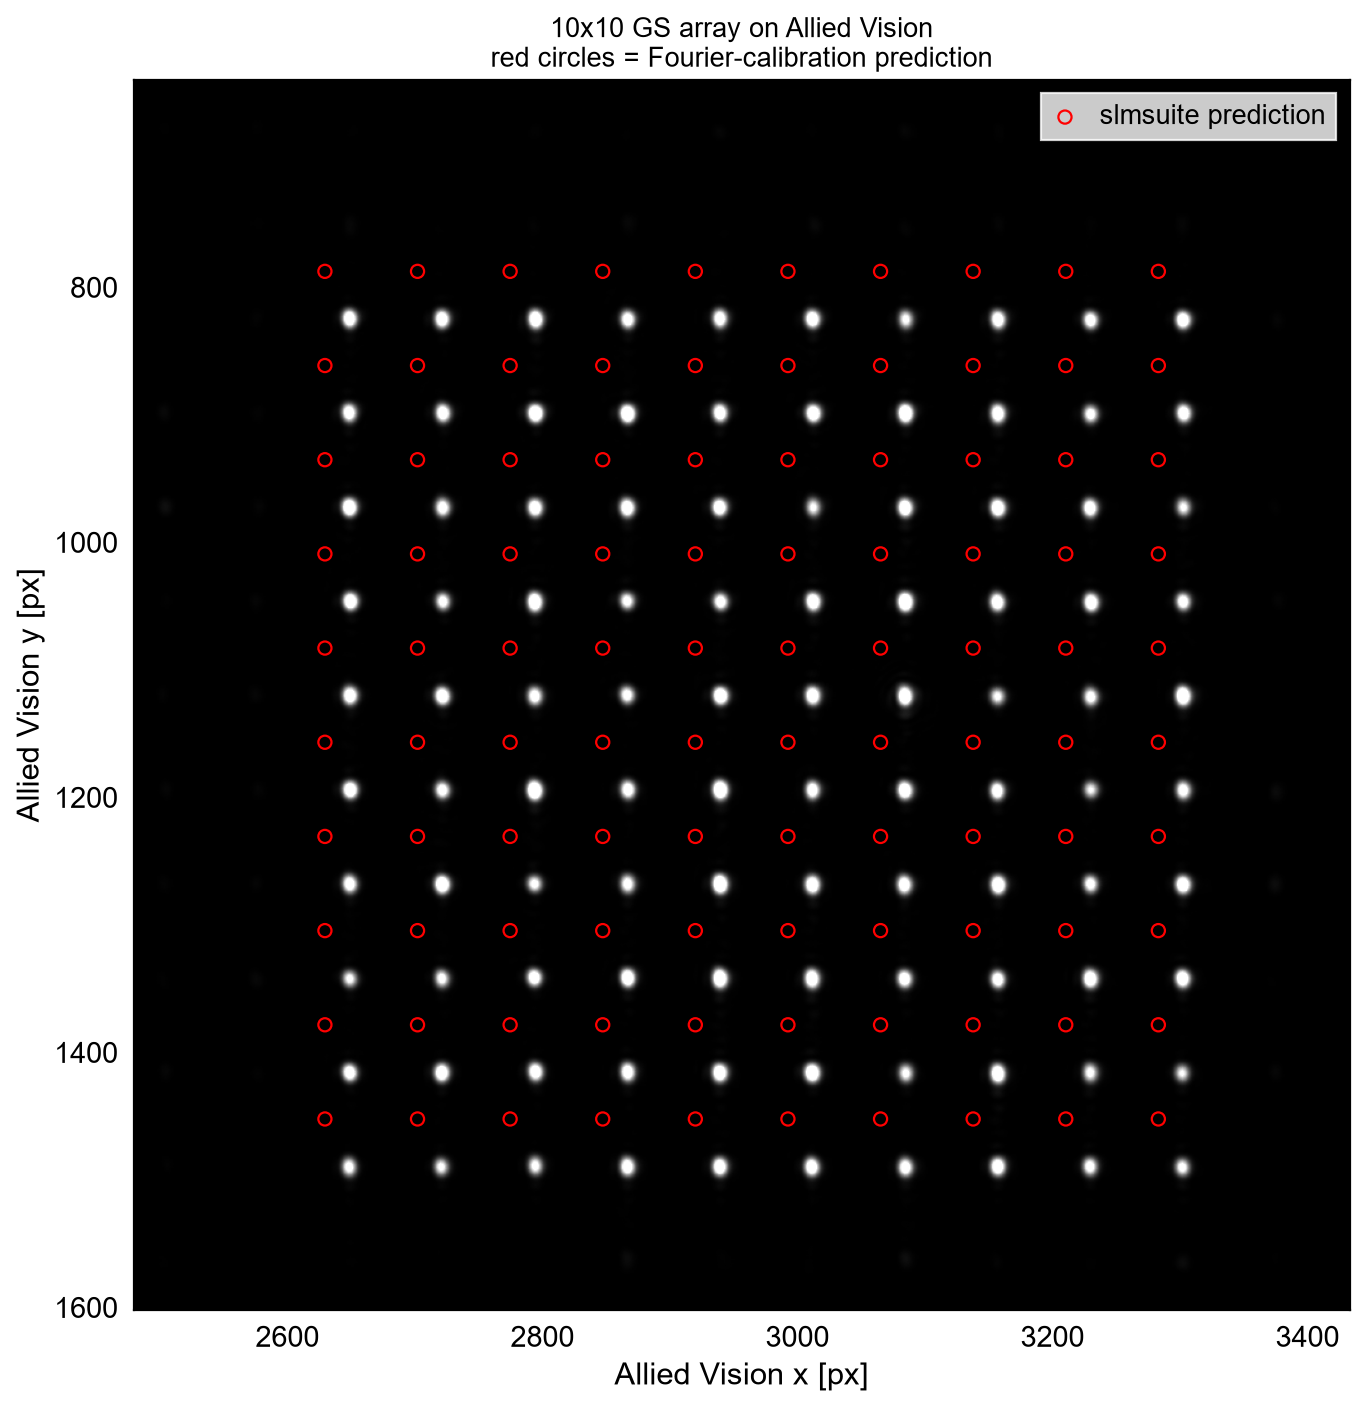


Display vmax used:
255.0


In [16]:
# ============================================================
# CELL 13 — VIEW 10x10 ON ALLIED VISION
#            + OVERLAY SLMSUITE PREDICTION
# ============================================================

pred = np.asarray(
    holo_10x10.spot_ij
)

print("Predicted spot array shape:")
print(pred.shape)

print("\nPredicted array center [x, y]:")
print(np.mean(pred, axis=1))


# ------------------------------------------------------------
# Plot a generous region around the predicted array
# ------------------------------------------------------------

MARGIN = 150

xmin = pred[0].min() - MARGIN
xmax = pred[0].max() + MARGIN

ymin = pred[1].min() - MARGIN
ymax = pred[1].max() + MARGIN


# Use a robust display scale so the saturated zeroth order
# doesn't make the 10x10 invisible.
region = img_av_GS[
    int(max(0, ymin)):int(min(img_av_GS.shape[0], ymax)),
    int(max(0, xmin)):int(min(img_av_GS.shape[1], xmax))
]

display_max = np.percentile(
    region,
    99.5
)


plt.figure(figsize=(11, 9))

plt.imshow(
    img_av_GS,
    cmap="gray",
    origin="upper",
    vmin=0,
    vmax=display_max
)

plt.scatter(
    pred[0],
    pred[1],
    facecolors="none",
    edgecolors="red",
    s=35,
    linewidths=1,
    label="slmsuite prediction"
)

plt.xlim(xmin, xmax)
plt.ylim(ymax, ymin)

plt.xlabel("Allied Vision x [px]")
plt.ylabel("Allied Vision y [px]")

plt.title(
    "10x10 GS array on Allied Vision\n"
    "red circles = Fourier-calibration prediction"
)

plt.legend()

plt.tight_layout()
plt.show()


print("\nDisplay vmax used:")
print(display_max)

In [17]:
# ============================================================
# CELL 14 — DETECT ACTUAL 10x10 SPOTS
#           AND MEASURE OFFSET FROM FOURIER PREDICTION
# ============================================================

from scipy.ndimage import gaussian_filter, maximum_filter


# ------------------------------------------------------------
# Predicted coordinates from slmsuite
# shape: (2, 100)
# ------------------------------------------------------------

pred_xy = np.asarray(
    holo_10x10.spot_ij
).T


# ------------------------------------------------------------
# Search region around the complete predicted array
# ------------------------------------------------------------

MARGIN = 100

XMIN = max(
    0,
    int(np.floor(pred_xy[:, 0].min() - MARGIN))
)

XMAX = min(
    img_av_GS.shape[1],
    int(np.ceil(pred_xy[:, 0].max() + MARGIN))
)

YMIN = max(
    0,
    int(np.floor(pred_xy[:, 1].min() - MARGIN))
)

YMAX = min(
    img_av_GS.shape[0],
    int(np.ceil(pred_xy[:, 1].max() + MARGIN))
)


roi = img_av_GS[
    YMIN:YMAX,
    XMIN:XMAX
].astype(float)


# ------------------------------------------------------------
# Light smoothing and local-max detection
# ------------------------------------------------------------

smooth = gaussian_filter(
    roi,
    sigma=1.5
)

local_max = (
    smooth
    ==
    maximum_filter(
        smooth,
        size=35
    )
)

coords = np.argwhere(
    local_max
)


brightness = smooth[
    coords[:, 0],
    coords[:, 1]
]


# Keep the 100 brightest peaks in this ROI
order = np.argsort(
    brightness
)[::-1]

coords = coords[
    order[:100]
]


# convert ROI coordinates -> full camera coordinates
actual_xy = np.column_stack([
    coords[:, 1] + XMIN,
    coords[:, 0] + YMIN
]).astype(float)


print("Detected actual spots:")
print(actual_xy.shape)


# ------------------------------------------------------------
# Sort a 10x10 grid:
# top row -> bottom row,
# left -> right within each row
# ------------------------------------------------------------

def sort_grid(points, nrows=10, ncols=10):

    points = np.asarray(points)

    # first sort by y
    order_y = np.argsort(
        points[:, 1]
    )

    sorted_indices = []

    for r in range(nrows):

        row_indices = order_y[
            r*ncols:
            (r+1)*ncols
        ]

        # left-to-right within this row
        row_indices = row_indices[
            np.argsort(
                points[row_indices, 0]
            )
        ]

        sorted_indices.extend(
            row_indices
        )

    return np.array(
        sorted_indices
    )


pred_order = sort_grid(
    pred_xy
)

actual_order = sort_grid(
    actual_xy
)


pred_sorted = pred_xy[
    pred_order
]

actual_sorted = actual_xy[
    actual_order
]


# ------------------------------------------------------------
# Difference actual - predicted
# ------------------------------------------------------------

delta_xy = (
    actual_sorted
    -
    pred_sorted
)


mean_shift = np.mean(
    delta_xy,
    axis=0
)

std_shift = np.std(
    delta_xy,
    axis=0
)


print("\n====================================")
print("CAMERA REGISTRATION")
print("====================================")

print("Mean actual - predicted shift [x,y] px:")
print(mean_shift)

print("\nStd of shift across 100 spots [x,y] px:")
print(std_shift)


# ------------------------------------------------------------
# Measured spacings
# ------------------------------------------------------------

actual_grid = actual_sorted.reshape(
    10,
    10,
    2
)

dx = np.linalg.norm(
    np.diff(
        actual_grid,
        axis=1
    ),
    axis=2
)

dy = np.linalg.norm(
    np.diff(
        actual_grid,
        axis=0
    ),
    axis=2
)


print("\nMeasured Allied Vision X spacing:")
print(
    np.mean(dx),
    "+/-",
    np.std(dx)
)

print("\nMeasured Allied Vision Y spacing:")
print(
    np.mean(dy),
    "+/-",
    np.std(dy)
)

Detected actual spots:
(100, 2)

CAMERA REGISTRATION
Mean actual - predicted shift [x,y] px:
[19.44031685 37.55406962]

Std of shift across 100 spots [x,y] px:
[0.4591749  0.44765292]

Measured Allied Vision X spacing:
72.61378423450827 +/- 0.6276103088964492

Measured Allied Vision Y spacing:
73.85766375881221 +/- 0.4841414866810823


FEEDBACK COORDINATE CORRECTION
Measured global shift [x,y] px:
[19.44031685 37.55406962]

Original mean position:
[2956.20968315 1119.85593038]

Corrected feedback mean position:
[2975.65 1157.41]


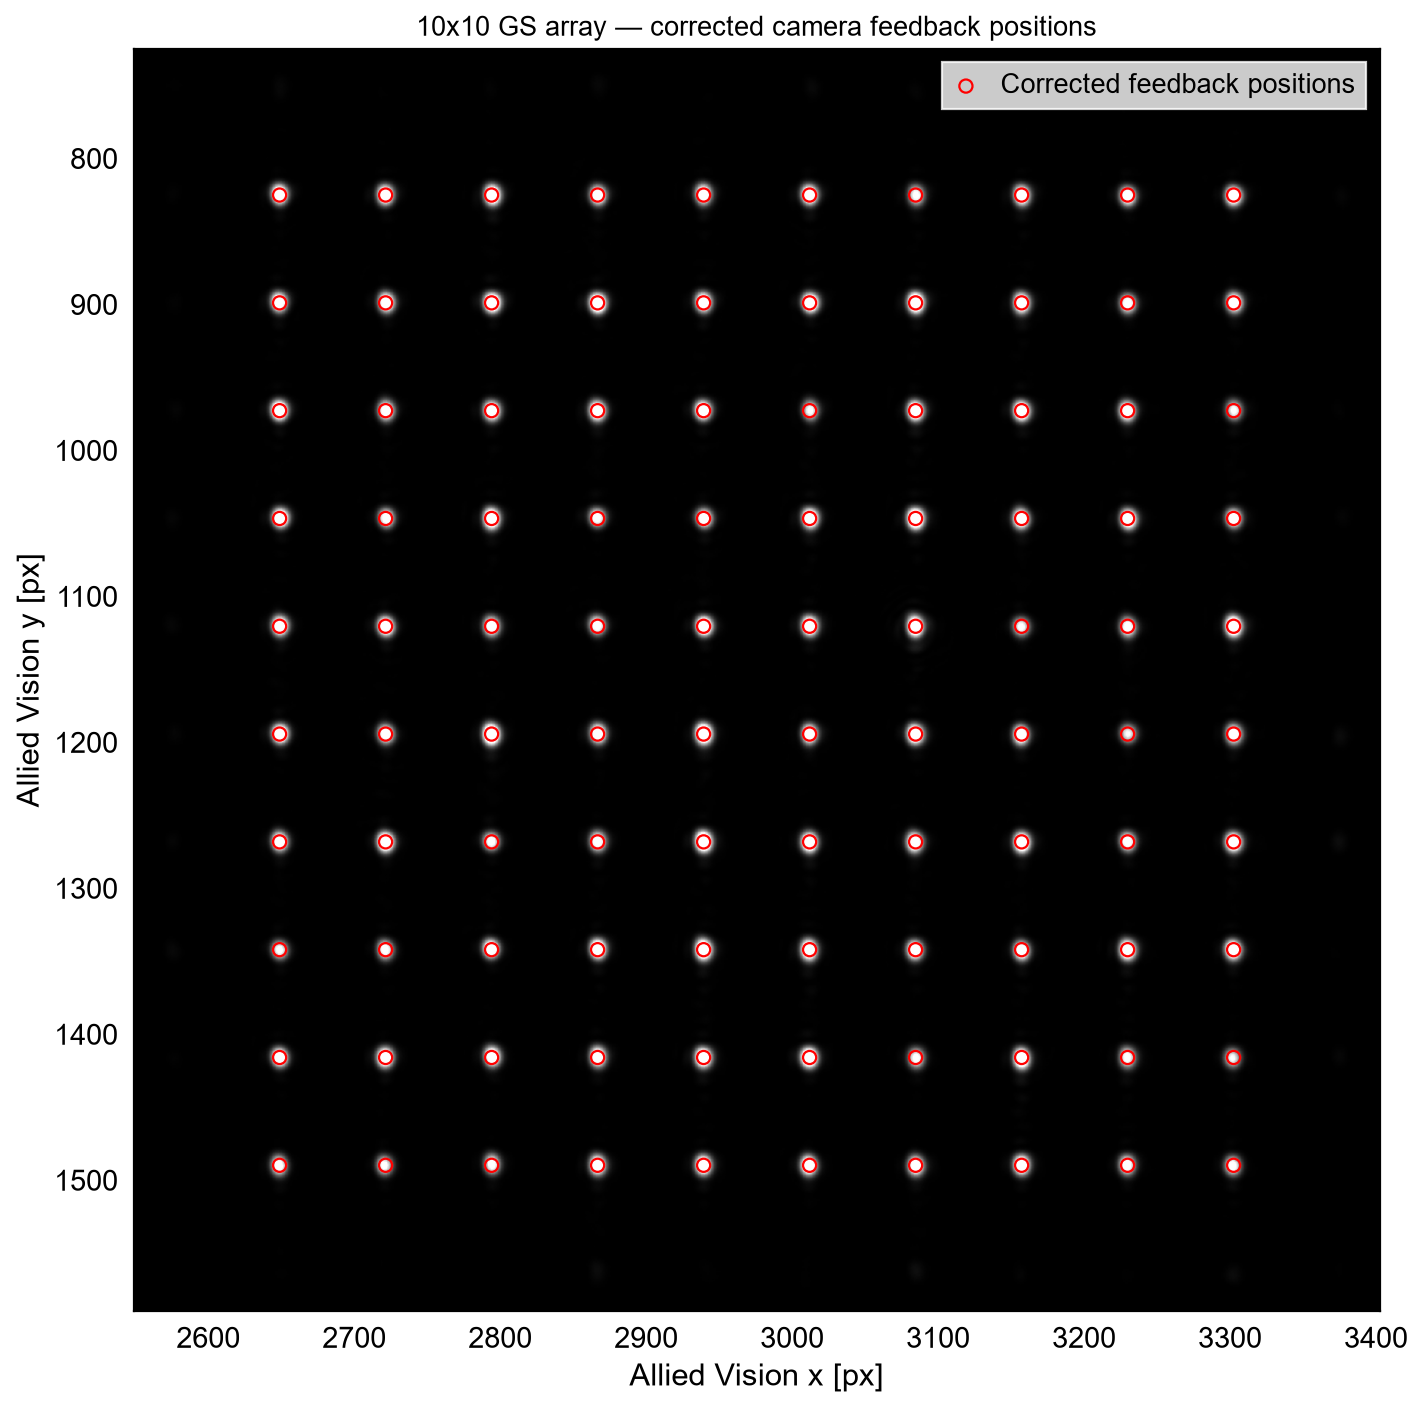

In [18]:
# ============================================================
# CELL 15 — CORRECT CAMERA FEEDBACK POSITIONS
#           USING THE MEASURED GLOBAL SHIFT
# ============================================================

MEAN_CAMERA_SHIFT = mean_shift.copy()

# Original slmsuite target positions, shape (2,100)
spot_ij_theory = np.asarray(
    holo_10x10.spot_ij
).copy()

# Corrected camera positions for feedback
spot_ij_feedback = (
    spot_ij_theory
    + MEAN_CAMERA_SHIFT[:, None]
)


print("====================================")
print("FEEDBACK COORDINATE CORRECTION")
print("====================================")

print("Measured global shift [x,y] px:")
print(MEAN_CAMERA_SHIFT)

print("\nOriginal mean position:")
print(
    np.mean(
        spot_ij_theory,
        axis=1
    )
)

print("\nCorrected feedback mean position:")
print(
    np.mean(
        spot_ij_feedback,
        axis=1
    )
)


# ============================================================
# VISUAL CHECK
# ============================================================

MARGIN = 100

xmin = spot_ij_feedback[0].min() - MARGIN
xmax = spot_ij_feedback[0].max() + MARGIN

ymin = spot_ij_feedback[1].min() - MARGIN
ymax = spot_ij_feedback[1].max() + MARGIN


region = img_av_GS[
    int(max(0, ymin)):int(min(img_av_GS.shape[0], ymax)),
    int(max(0, xmin)):int(min(img_av_GS.shape[1], xmax))
]

display_max = np.percentile(
    region,
    99.5
)


plt.figure(figsize=(10, 9))

plt.imshow(
    img_av_GS,
    cmap="gray",
    origin="upper",
    vmin=0,
    vmax=display_max
)

plt.scatter(
    spot_ij_feedback[0],
    spot_ij_feedback[1],
    facecolors="none",
    edgecolors="red",
    s=35,
    linewidths=1,
    label="Corrected feedback positions"
)

plt.xlim(xmin, xmax)
plt.ylim(ymax, ymin)

plt.xlabel("Allied Vision x [px]")
plt.ylabel("Allied Vision y [px]")

plt.title(
    "10x10 GS array — corrected camera feedback positions"
)

plt.legend()

plt.tight_layout()
plt.show()

TWEEZER SATURATION CHECK
Feedback ROI width [px]: 15

Brightest tweezer max count:
106

Median tweezer max count:
78.0

10th / 90th percentile max count:
55.8 96.0

Number of tweezers containing >=1 saturated pixel:
0 / 100

Total saturated pixels inside all 100 tweezer ROIs:
0

Worst saturated-pixel count in one tweezer ROI:
0


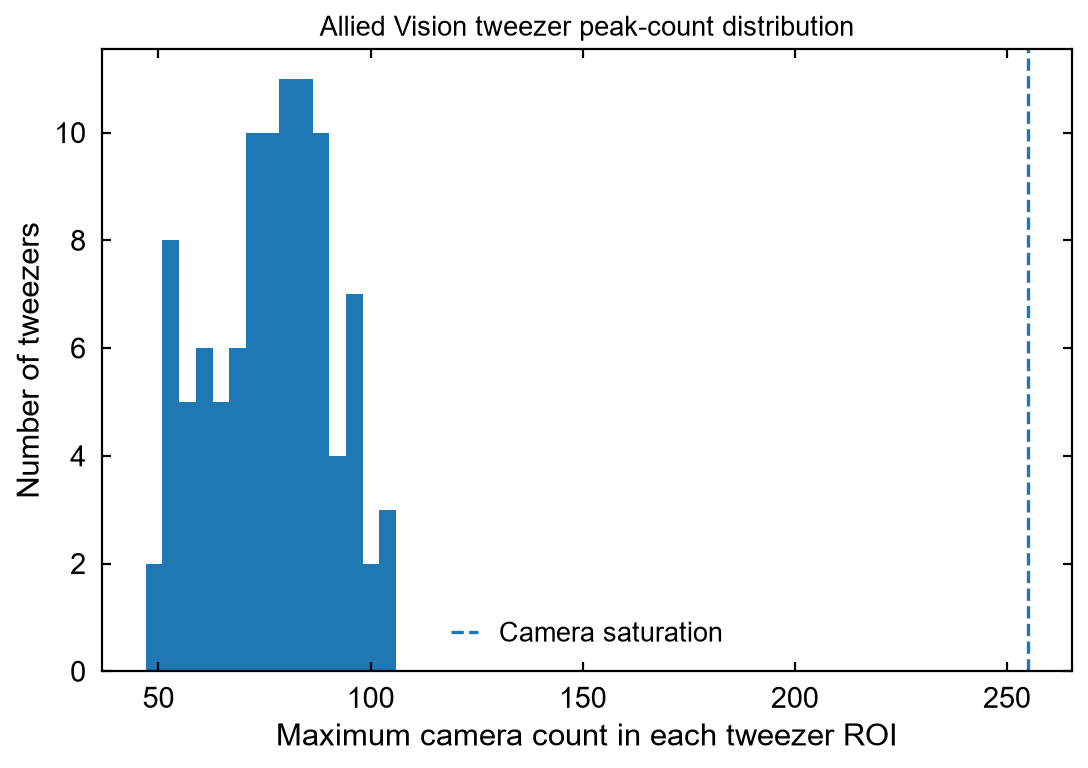

In [21]:
# ============================================================
# CELL 16 — SATURATION CHECK ON THE 100 TWEEZER ROIs
# ============================================================

# Use the same 15-pixel-wide square ROI that we will later
# use for experimental_spot feedback.
ROI_WIDTH = 15
HALF = ROI_WIDTH // 2

CAMERA_MAX = 255   # uint8 Allied Vision image

spot_maxima = []
spot_sat_pixels = []
spot_mean_counts = []

for i in range(100):

    x = spot_ij_feedback[0, i]
    y = spot_ij_feedback[1, i]

    xi = int(round(x))
    yi = int(round(y))

    cut = img_av_GS[
        yi-HALF : yi+HALF+1,
        xi-HALF : xi+HALF+1
    ]

    spot_maxima.append(
        np.max(cut)
    )

    spot_sat_pixels.append(
        np.sum(cut >= CAMERA_MAX)
    )

    spot_mean_counts.append(
        np.mean(cut)
    )


spot_maxima = np.array(spot_maxima)
spot_sat_pixels = np.array(spot_sat_pixels)
spot_mean_counts = np.array(spot_mean_counts)


print("====================================")
print("TWEEZER SATURATION CHECK")
print("====================================")

print("Feedback ROI width [px]:", ROI_WIDTH)

print("\nBrightest tweezer max count:")
print(spot_maxima.max())

print("\nMedian tweezer max count:")
print(np.median(spot_maxima))

print("\n10th / 90th percentile max count:")
print(
    np.percentile(spot_maxima, 10),
    np.percentile(spot_maxima, 90)
)

print("\nNumber of tweezers containing >=1 saturated pixel:")
print(
    np.sum(spot_sat_pixels > 0),
    "/ 100"
)

print("\nTotal saturated pixels inside all 100 tweezer ROIs:")
print(
    np.sum(spot_sat_pixels)
)

print("\nWorst saturated-pixel count in one tweezer ROI:")
print(
    spot_sat_pixels.max()
)


# ------------------------------------------------------------
# Histogram of peak counts across all 100 tweezers
# ------------------------------------------------------------

plt.figure(figsize=(7, 5))

plt.hist(
    spot_maxima,
    bins=15
)

plt.axvline(
    255,
    linestyle="--",
    label="Camera saturation"
)

plt.xlabel("Maximum camera count in each tweezer ROI")
plt.ylabel("Number of tweezers")

plt.title(
    "Allied Vision tweezer peak-count distribution"
)

plt.legend()

plt.tight_layout()
plt.show()

In [20]:
# ============================================================
# REACQUIRE AFTER REDUCING OPTICAL POWER
# ============================================================

cam.flush()

img_av_GS = cam.get_image()

print("Image max:", img_av_GS.max())
print(
    "Full-frame saturated pixels:",
    np.sum(img_av_GS >= 255)
)

Image max: 119
Full-frame saturated pixels: 0


GS BASELINE — ALLIED VISION
Integrated-power CV [%]:
19.76983403944927

Peak-intensity CV [%]:
18.79370509036235

Normalized power min / max:
0.5875689867476397 1.425685017648442

Normalized power 10th / 90th percentile:
0.7280167162883527 1.2546587118528154

Mean local background [counts]:
0.04


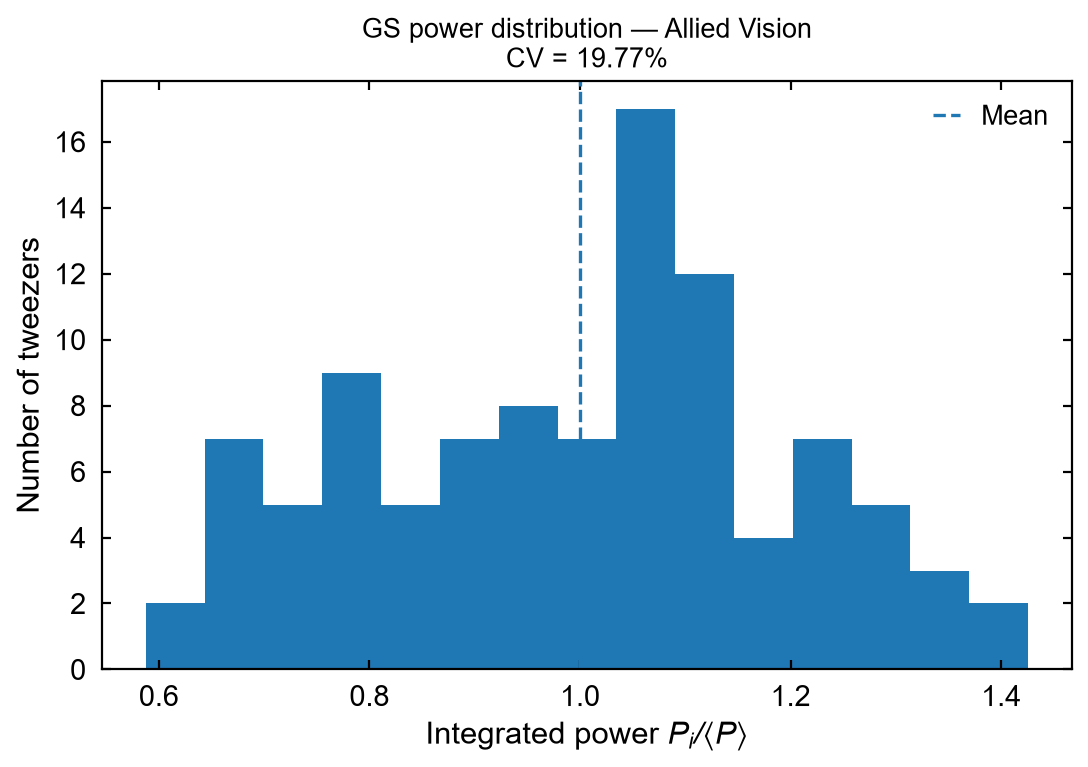

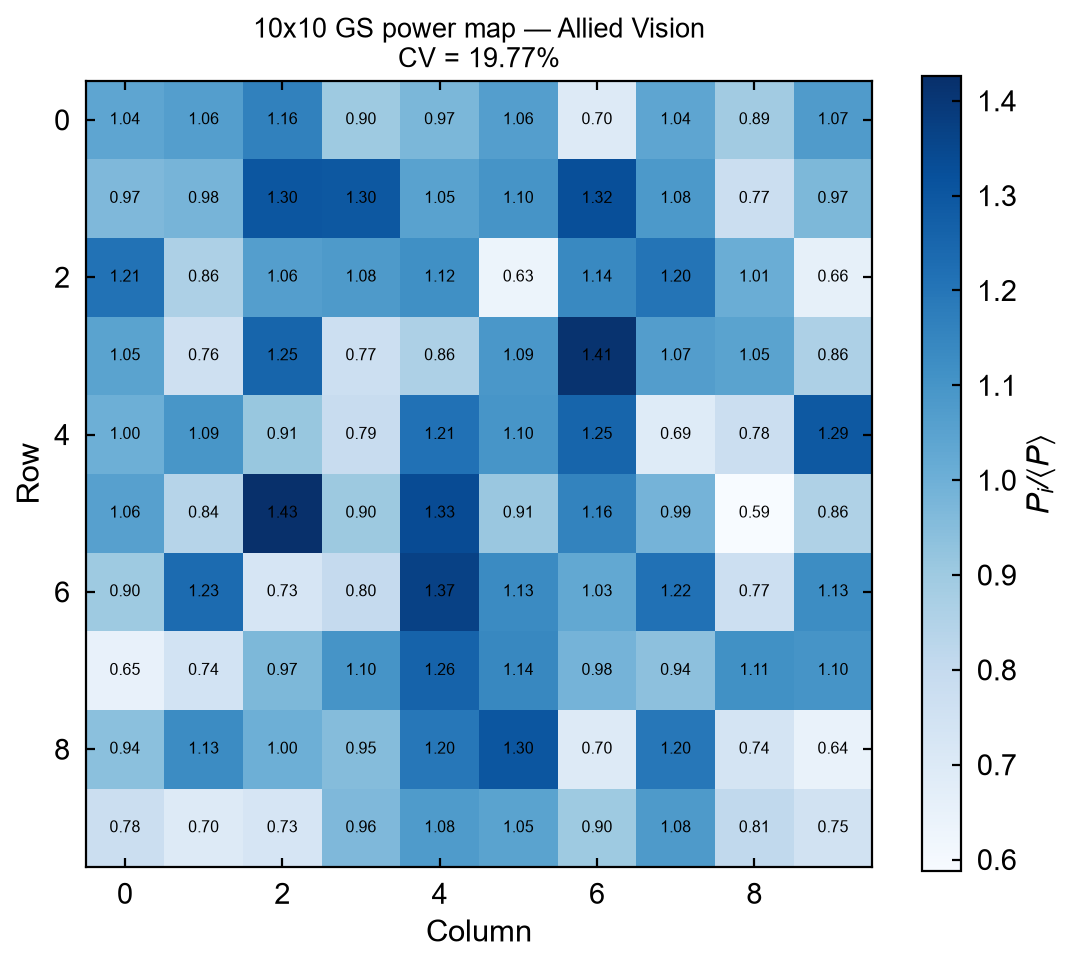

In [22]:
# ============================================================
# CELL 17 — GS BASELINE POWER HOMOGENEITY ON ALLIED VISION
# ============================================================

ROI_WIDTH = 15
HALF = ROI_WIDTH // 2

# Background annulus around each spot
BG_R_IN = 10
BG_R_OUT = 15


powers_GS = []
peaks_GS = []
backgrounds_GS = []

yy_full, xx_full = np.indices(img_av_GS.shape)


for i in range(100):

    x0 = spot_ij_feedback[0, i]
    y0 = spot_ij_feedback[1, i]

    xi = int(round(x0))
    yi = int(round(y0))


    # --------------------------------------------------------
    # Small local region large enough for ROI + background
    # --------------------------------------------------------

    R = BG_R_OUT + 2

    x1 = xi - R
    x2 = xi + R + 1

    y1 = yi - R
    y2 = yi + R + 1

    patch = img_av_GS[
        y1:y2,
        x1:x2
    ].astype(float)


    yy, xx = np.indices(
        patch.shape
    )

    xc = x0 - x1
    yc = y0 - y1

    rr = np.sqrt(
        (xx - xc)**2
        +
        (yy - yc)**2
    )


    # --------------------------------------------------------
    # Local background
    # --------------------------------------------------------

    bg_mask = (
        (rr >= BG_R_IN)
        &
        (rr <= BG_R_OUT)
    )

    bg = np.median(
        patch[bg_mask]
    )


    # --------------------------------------------------------
    # 15 x 15 feedback-like integration region
    # --------------------------------------------------------

    roi_mask = (
        (np.abs(xx - xc) <= HALF)
        &
        (np.abs(yy - yc) <= HALF)
    )

    corrected = (
        patch - bg
    )

    # For power integration, don't let negative noise subtract.
    corrected_positive = np.clip(
        corrected,
        0,
        None
    )

    power = np.sum(
        corrected_positive[roi_mask]
    )

    peak = np.max(
        corrected[roi_mask]
    )


    powers_GS.append(power)
    peaks_GS.append(peak)
    backgrounds_GS.append(bg)


powers_GS = np.asarray(
    powers_GS
)

peaks_GS = np.asarray(
    peaks_GS
)

backgrounds_GS = np.asarray(
    backgrounds_GS
)


# ============================================================
# NORMALIZE + STATISTICS
# ============================================================

powers_GS_norm = (
    powers_GS
    /
    np.mean(powers_GS)
)

peaks_GS_norm = (
    peaks_GS
    /
    np.mean(peaks_GS)
)


CV_power_GS = (
    100
    * np.std(
        powers_GS,
        ddof=1
    )
    / np.mean(powers_GS)
)

CV_peak_GS = (
    100
    * np.std(
        peaks_GS,
        ddof=1
    )
    / np.mean(peaks_GS)
)


print("====================================")
print("GS BASELINE — ALLIED VISION")
print("====================================")

print("Integrated-power CV [%]:")
print(CV_power_GS)

print("\nPeak-intensity CV [%]:")
print(CV_peak_GS)

print("\nNormalized power min / max:")
print(
    powers_GS_norm.min(),
    powers_GS_norm.max()
)

print("\nNormalized power 10th / 90th percentile:")
print(
    np.percentile(powers_GS_norm, 10),
    np.percentile(powers_GS_norm, 90)
)

print("\nMean local background [counts]:")
print(
    np.mean(backgrounds_GS)
)


# ============================================================
# SORT INTO PHYSICAL 10x10 GRID FOR DISPLAY
#
# pred_order was already generated in Cell 14.
# It maps row-by-row spatial order to the hologram indices.
# ============================================================

power_map_GS = (
    powers_GS_norm[pred_order]
    .reshape(10, 10)
)


# ============================================================
# PLOT 1 — HISTOGRAM
# ============================================================

plt.figure(figsize=(7, 5))

plt.hist(
    powers_GS_norm,
    bins=15
)

plt.axvline(
    1.0,
    linestyle="--",
    label="Mean"
)

plt.xlabel(
    r"Integrated power $P_i/\langle P\rangle$"
)

plt.ylabel(
    "Number of tweezers"
)

plt.title(
    f"GS power distribution — Allied Vision\n"
    f"CV = {CV_power_GS:.2f}%"
)

plt.legend()

plt.tight_layout()
plt.show()


# ============================================================
# PLOT 2 — 10x10 POWER MAP
# ============================================================

plt.figure(figsize=(7, 6))

im = plt.imshow(
    power_map_GS,
    origin="upper"
)

plt.colorbar(
    im,
    label=r"$P_i/\langle P\rangle$"
)

for r in range(10):
    for c in range(10):

        plt.text(
            c,
            r,
            f"{power_map_GS[r,c]:.2f}",
            ha="center",
            va="center",
            fontsize=7
        )

plt.xlabel("Column")
plt.ylabel("Row")

plt.title(
    f"10x10 GS power map — Allied Vision\n"
    f"CV = {CV_power_GS:.2f}%"
)

plt.tight_layout()
plt.show()

In [23]:
# ============================================================
# CELL 18 — INSTALL EXPERIMENTAL FEEDBACK COORDINATES
# ============================================================

# Save the original Fourier-calibration prediction
# so we can always restore it.
spot_ij_theory = np.asarray(
    holo_10x10.spot_ij
).copy()


# Use the globally shifted coordinates that we visually verified.
holo_10x10.spot_ij = (
    spot_ij_feedback.copy()
)


# Set the camera integration width used by experimental_spot.
holo_10x10.spot_integration_width_ij = 15


print("====================================")
print("EXPERIMENTAL FEEDBACK SETUP")
print("====================================")

print("Number of feedback spots:")
print(holo_10x10.spot_ij.shape[1])

print("\nIntegration width [px]:")
print(holo_10x10.spot_integration_width_ij)

print("\nMean theoretical camera position:")
print(
    np.mean(
        spot_ij_theory,
        axis=1
    )
)

print("\nMean experimental feedback position:")
print(
    np.mean(
        holo_10x10.spot_ij,
        axis=1
    )
)

print("\nApplied mean shift [x,y] px:")
print(
    np.mean(
        holo_10x10.spot_ij
        -
        spot_ij_theory,
        axis=1
    )
)

EXPERIMENTAL FEEDBACK SETUP
Number of feedback spots:
100

Integration width [px]:
15

Mean theoretical camera position:
[2956.20968315 1119.85593038]

Mean experimental feedback position:
[2975.65 1157.41]

Applied mean shift [x,y] px:
[19.44031685 37.55406962]


In [24]:
# ============================================================
# CELL 19 — SLMSUITE NATIVE EXPERIMENTAL-SPOT BASELINE
# ============================================================

# Force a fresh camera acquisition inside slmsuite
holo_10x10.img_ij = None
holo_10x10.img_knm = None


# Acquire the experimental image in camera coordinates
holo_10x10.measure(
    basis="ij"
)


print("====================================")
print("SLMSUITE MEASUREMENT CHECK")
print("====================================")

print("img_ij shape:")
print(np.shape(holo_10x10.img_ij))

print("\nimg_ij dtype:")
print(np.asarray(holo_10x10.img_ij).dtype)

print("\nimg_ij min/max:")
print(
    np.nanmin(holo_10x10.img_ij),
    np.nanmax(holo_10x10.img_ij)
)


# ------------------------------------------------------------
# Integrate powers at the 100 corrected camera positions
#
# slmsuite stores img_ij as field amplitude, so square it
# to obtain intensity/power before integration.
# ------------------------------------------------------------

pwr_slmsuite_GS = analysis.take(
    np.square(
        np.asarray(
            holo_10x10.img_ij,
            dtype=float
        )
    ),

    holo_10x10.spot_ij,

    holo_10x10.spot_integration_width_ij,

    centered=True,
    integrate=True
)


pwr_slmsuite_GS = np.asarray(
    pwr_slmsuite_GS,
    dtype=float
)


pwr_slmsuite_GS_norm = (
    pwr_slmsuite_GS
    /
    np.mean(pwr_slmsuite_GS)
)


CV_slmsuite_GS = (
    100
    * np.std(
        pwr_slmsuite_GS,
        ddof=1
    )
    / np.mean(pwr_slmsuite_GS)
)


print("\n====================================")
print("SLMSUITE GS BASELINE")
print("====================================")

print("Integrated-power CV [%]:")
print(CV_slmsuite_GS)

print("\nNormalized power min / max:")
print(
    pwr_slmsuite_GS_norm.min(),
    pwr_slmsuite_GS_norm.max()
)

print("\n10th / 90th percentile:")
print(
    np.percentile(
        pwr_slmsuite_GS_norm,
        10
    ),
    np.percentile(
        pwr_slmsuite_GS_norm,
        90
    )
)

print("\nManual baseline from Cell 17 [%]:")
print(CV_power_GS)

SLMSUITE MEASUREMENT CHECK
img_ij shape:
(3672, 5496)

img_ij dtype:
float32

img_ij min/max:
0.0 10.816654

SLMSUITE GS BASELINE
Integrated-power CV [%]:
20.040695438802018

Normalized power min / max:
0.5799331939483525 1.4692707371360276

10th / 90th percentile:
0.7353712870580732 1.2746531686380524

Manual baseline from Cell 17 [%]:
19.76983403944927


In [25]:
# ============================================================
# CELL 20 — FIRST EXPERIMENTAL WGS TEST: 3 ITERATIONS
# ============================================================

# Save the current GS state first, so we have a checkpoint.
phase_before_WGS = holo_10x10.get_phase().copy()

print("====================================")
print("STARTING EXPERIMENTAL WGS")
print("====================================")

print("Camera exposure [us]:")
print(cam.get_exposure() * 1e6)

print("\nCurrent GS baseline CV [%]:")
print(CV_slmsuite_GS)

print("\nRunning 3 experimental WGS-Kim iterations...")


holo_10x10.optimize(
    method="WGS-Kim",

    maxiter=3,

    feedback="experimental_spot",

    stat_groups=[
        "computational_spot",
        "experimental_spot"
    ],

    fixed_phase=False,

    verbose=True
)


print("\n====================================")
print("3 WGS ITERATIONS COMPLETE")
print("====================================")

phase_after_WGS3 = holo_10x10.get_phase().copy()

print("Phase finite?")
print(np.all(np.isfinite(phase_after_WGS3)))

print("\nPhase shape:")
print(phase_after_WGS3.shape)

STARTING EXPERIMENTAL WGS
Camera exposure [us]:
29.681

Current GS baseline CV [%]:
20.040695438802018

Running 3 experimental WGS-Kim iterations...


  0%|          | 0/3 [00:00<?, ?it/s]


3 WGS ITERATIONS COMPLETE
Phase finite?
True

Phase shape:
(1200, 1920)


WGS3 RESULT
GS baseline CV [%]:
20.040695438802018

WGS3 CV [%]:
5.626681313051193

Improvement factor:
3.561725700070706

Normalized power min / max:
0.9062331937591283 1.1904476636610914

10th / 90th percentile:
0.9359901141262644 1.0646913156864237

Brightest tweezer camera count:
87.00000323838685

Median tweezer camera count:
75.00000763159278

Tweezers containing saturated pixels:
0 / 100


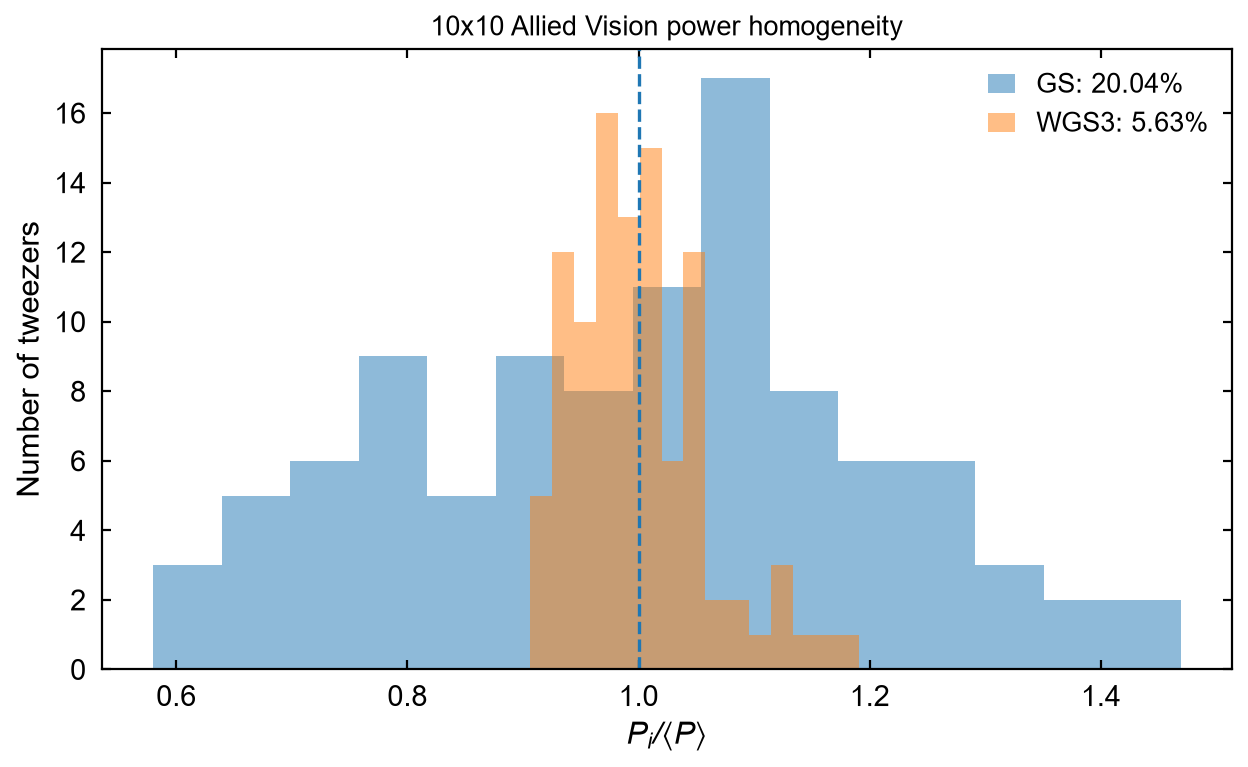

In [26]:
# ============================================================
# CELL 21 — MEASURE WGS3 RESULT + CHECK SATURATION
# ============================================================

# Force a fresh camera measurement
holo_10x10.img_ij = None
holo_10x10.img_knm = None

holo_10x10.measure(
    basis="ij"
)


# ============================================================
# INTEGRATED POWERS USING THE SAME SLMSUITE METHOD AS BEFORE
# ============================================================

pwr_WGS3 = analysis.take(
    np.square(
        np.asarray(
            holo_10x10.img_ij,
            dtype=float
        )
    ),

    holo_10x10.spot_ij,

    holo_10x10.spot_integration_width_ij,

    centered=True,
    integrate=True
)

pwr_WGS3 = np.asarray(
    pwr_WGS3,
    dtype=float
)

pwr_WGS3_norm = (
    pwr_WGS3
    /
    np.mean(pwr_WGS3)
)

CV_WGS3 = (
    100
    * np.std(
        pwr_WGS3,
        ddof=1
    )
    / np.mean(pwr_WGS3)
)


# ============================================================
# SATURATION CHECK
#
# holo.img_ij is field amplitude, so square it to get
# camera intensity again.
# ============================================================

img_WGS3_intensity = np.square(
    np.asarray(
        holo_10x10.img_ij,
        dtype=float
    )
)


ROI_WIDTH = 15
HALF = ROI_WIDTH // 2

spot_maxima_WGS3 = []
spot_sat_WGS3 = []

for i in range(100):

    x = holo_10x10.spot_ij[0, i]
    y = holo_10x10.spot_ij[1, i]

    xi = int(round(x))
    yi = int(round(y))

    cut = img_WGS3_intensity[
        yi-HALF:yi+HALF+1,
        xi-HALF:xi+HALF+1
    ]

    spot_maxima_WGS3.append(
        np.max(cut)
    )

    spot_sat_WGS3.append(
        np.sum(cut >= 255)
    )


spot_maxima_WGS3 = np.asarray(
    spot_maxima_WGS3
)

spot_sat_WGS3 = np.asarray(
    spot_sat_WGS3
)


# ============================================================
# PRINT SUMMARY
# ============================================================

print("====================================")
print("WGS3 RESULT")
print("====================================")

print("GS baseline CV [%]:")
print(CV_slmsuite_GS)

print("\nWGS3 CV [%]:")
print(CV_WGS3)

print("\nImprovement factor:")
print(
    CV_slmsuite_GS / CV_WGS3
)

print("\nNormalized power min / max:")
print(
    pwr_WGS3_norm.min(),
    pwr_WGS3_norm.max()
)

print("\n10th / 90th percentile:")
print(
    np.percentile(pwr_WGS3_norm, 10),
    np.percentile(pwr_WGS3_norm, 90)
)

print("\nBrightest tweezer camera count:")
print(
    spot_maxima_WGS3.max()
)

print("\nMedian tweezer camera count:")
print(
    np.median(spot_maxima_WGS3)
)

print("\nTweezers containing saturated pixels:")
print(
    np.sum(spot_sat_WGS3 > 0),
    "/ 100"
)


# ============================================================
# HISTOGRAM: GS vs WGS3
# ============================================================

plt.figure(figsize=(8, 5))

plt.hist(
    pwr_slmsuite_GS_norm,
    bins=15,
    alpha=0.5,
    label=f"GS: {CV_slmsuite_GS:.2f}%"
)

plt.hist(
    pwr_WGS3_norm,
    bins=15,
    alpha=0.5,
    label=f"WGS3: {CV_WGS3:.2f}%"
)

plt.axvline(
    1.0,
    linestyle="--"
)

plt.xlabel(
    r"$P_i/\langle P\rangle$"
)

plt.ylabel(
    "Number of tweezers"
)

plt.title(
    "10x10 Allied Vision power homogeneity"
)

plt.legend()

plt.tight_layout()
plt.show()

In [27]:
# ============================================================
# CELL 22 — SAVE WGS3 CHECKPOINT + RUN 2 MORE WGS ITERATIONS
# ============================================================

# Save the current experimentally corrected state
phase_WGS3 = holo_10x10.get_phase().copy()

print("====================================")
print("WGS3 CHECKPOINT SAVED")
print("====================================")

print("Current measured CV [%]:")
print(CV_WGS3)

print("\nCurrent normalized min / max:")
print(
    pwr_WGS3_norm.min(),
    pwr_WGS3_norm.max()
)

print("\nRunning 2 additional experimental WGS iterations...")


holo_10x10.optimize(
    method="WGS-Kim",

    maxiter=2,

    feedback="experimental_spot",

    stat_groups=[
        "computational_spot",
        "experimental_spot"
    ],

    fixed_phase=False,

    verbose=True
)


phase_WGS5 = holo_10x10.get_phase().copy()


print("\n====================================")
print("TOTAL 5 WGS ITERATIONS COMPLETE")
print("====================================")

print("Phase finite?")
print(
    np.all(
        np.isfinite(
            phase_WGS5
        )
    )
)

print("\nPhase shape:")
print(
    phase_WGS5.shape
)

WGS3 CHECKPOINT SAVED
Current measured CV [%]:
5.626681313051193

Current normalized min / max:
0.9062331937591283 1.1904476636610914

Running 2 additional experimental WGS iterations...


  0%|          | 0/2 [00:00<?, ?it/s]


TOTAL 5 WGS ITERATIONS COMPLETE
Phase finite?
True

Phase shape:
(1200, 1920)


WGS5 RESULT
GS baseline CV [%]:
20.040695438802018

WGS3 CV [%]:
5.626681313051193

WGS5 CV [%]:
4.9179161776215174

Improvement GS -> WGS5:
4.07503802728383

Normalized power min / max:
0.8922368060883981 1.1014905119947247

10th / 90th percentile:
0.9353656783219633 1.063965751678844

Brightest tweezer camera count:
88.99999640972601

Median tweezer camera count:
77.99999187771755

Tweezers containing saturated pixels:
0 / 100


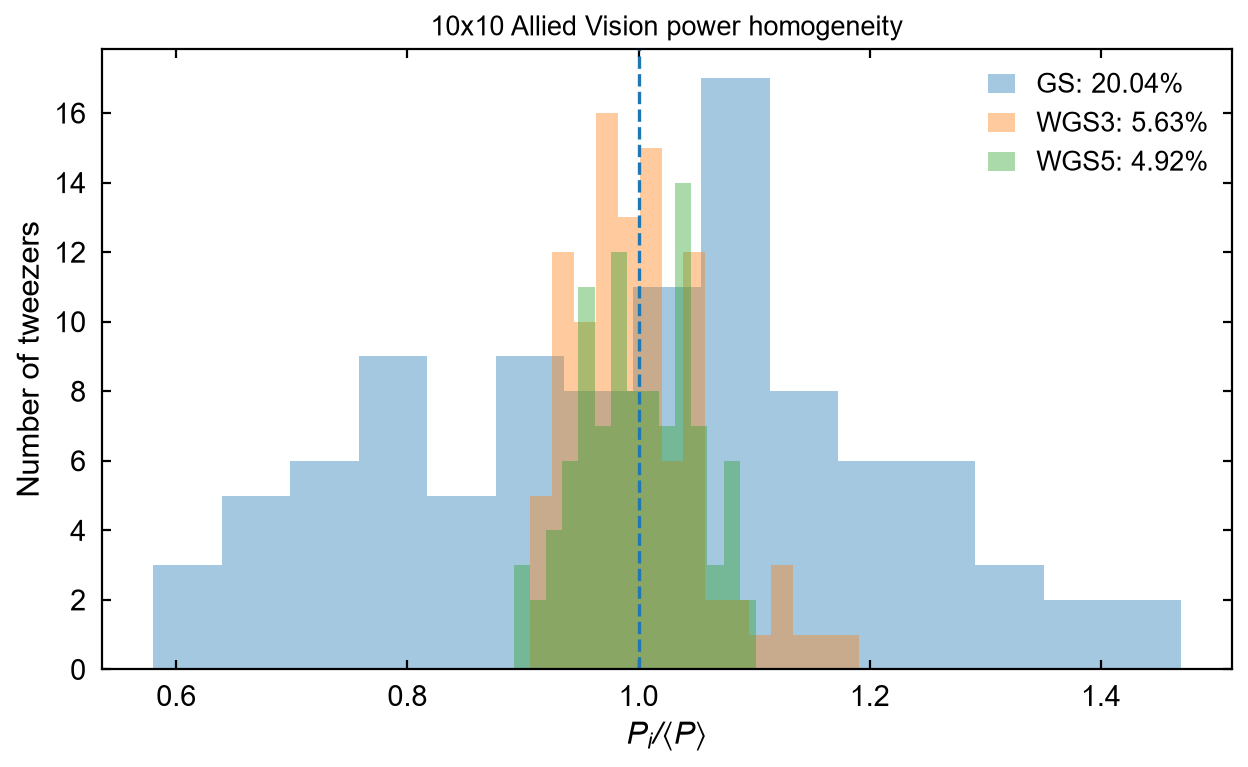

In [28]:
# ============================================================
# CELL 23 — MEASURE WGS5 RESULT + CHECK SATURATION
# ============================================================

# Fresh camera measurement
holo_10x10.img_ij = None
holo_10x10.img_knm = None

holo_10x10.measure(
    basis="ij"
)


# ============================================================
# INTEGRATED POWERS
# ============================================================

pwr_WGS5 = analysis.take(
    np.square(
        np.asarray(
            holo_10x10.img_ij,
            dtype=float
        )
    ),

    holo_10x10.spot_ij,

    holo_10x10.spot_integration_width_ij,

    centered=True,
    integrate=True
)

pwr_WGS5 = np.asarray(
    pwr_WGS5,
    dtype=float
)

pwr_WGS5_norm = (
    pwr_WGS5
    /
    np.mean(pwr_WGS5)
)

CV_WGS5 = (
    100
    * np.std(
        pwr_WGS5,
        ddof=1
    )
    / np.mean(pwr_WGS5)
)


# ============================================================
# SATURATION CHECK
# ============================================================

img_WGS5_intensity = np.square(
    np.asarray(
        holo_10x10.img_ij,
        dtype=float
    )
)

ROI_WIDTH = 15
HALF = ROI_WIDTH // 2

spot_maxima_WGS5 = []
spot_sat_WGS5 = []

for i in range(100):

    x = holo_10x10.spot_ij[0, i]
    y = holo_10x10.spot_ij[1, i]

    xi = int(round(x))
    yi = int(round(y))

    cut = img_WGS5_intensity[
        yi-HALF:yi+HALF+1,
        xi-HALF:xi+HALF+1
    ]

    spot_maxima_WGS5.append(
        np.max(cut)
    )

    spot_sat_WGS5.append(
        np.sum(cut >= 255)
    )


spot_maxima_WGS5 = np.asarray(
    spot_maxima_WGS5
)

spot_sat_WGS5 = np.asarray(
    spot_sat_WGS5
)


# ============================================================
# SUMMARY
# ============================================================

print("====================================")
print("WGS5 RESULT")
print("====================================")

print("GS baseline CV [%]:")
print(CV_slmsuite_GS)

print("\nWGS3 CV [%]:")
print(CV_WGS3)

print("\nWGS5 CV [%]:")
print(CV_WGS5)

print("\nImprovement GS -> WGS5:")
print(
    CV_slmsuite_GS / CV_WGS5
)

print("\nNormalized power min / max:")
print(
    pwr_WGS5_norm.min(),
    pwr_WGS5_norm.max()
)

print("\n10th / 90th percentile:")
print(
    np.percentile(pwr_WGS5_norm, 10),
    np.percentile(pwr_WGS5_norm, 90)
)

print("\nBrightest tweezer camera count:")
print(
    spot_maxima_WGS5.max()
)

print("\nMedian tweezer camera count:")
print(
    np.median(spot_maxima_WGS5)
)

print("\nTweezers containing saturated pixels:")
print(
    np.sum(spot_sat_WGS5 > 0),
    "/ 100"
)


# ============================================================
# HISTOGRAM COMPARISON
# ============================================================

plt.figure(figsize=(8, 5))

plt.hist(
    pwr_slmsuite_GS_norm,
    bins=15,
    alpha=0.4,
    label=f"GS: {CV_slmsuite_GS:.2f}%"
)

plt.hist(
    pwr_WGS3_norm,
    bins=15,
    alpha=0.4,
    label=f"WGS3: {CV_WGS3:.2f}%"
)

plt.hist(
    pwr_WGS5_norm,
    bins=15,
    alpha=0.4,
    label=f"WGS5: {CV_WGS5:.2f}%"
)

plt.axvline(
    1.0,
    linestyle="--"
)

plt.xlabel(
    r"$P_i/\langle P\rangle$"
)

plt.ylabel(
    "Number of tweezers"
)

plt.title(
    "10x10 Allied Vision power homogeneity"
)

plt.legend()

plt.tight_layout()
plt.show()

In [29]:
# ============================================================
# MEASURE CAMERA / POWER READOUT REPEATABILITY
# ============================================================

N_FRAMES = 10

all_powers = []

for n in range(N_FRAMES):

    holo_10x10.img_ij = None
    holo_10x10.img_knm = None

    holo_10x10.measure(
        basis="ij"
    )

    pwr = analysis.take(
        np.square(
            np.asarray(
                holo_10x10.img_ij,
                dtype=float
            )
        ),

        holo_10x10.spot_ij,

        holo_10x10.spot_integration_width_ij,

        centered=True,
        integrate=True
    )

    all_powers.append(
        np.asarray(pwr, dtype=float)
    )


all_powers = np.asarray(all_powers)   # shape = (N_FRAMES, 100)


# Mean power for each tweezer over repeated frames
mean_per_spot = np.mean(
    all_powers,
    axis=0
)

# Temporal standard deviation of each tweezer
std_per_spot = np.std(
    all_powers,
    axis=0,
    ddof=1
)

# Relative frame-to-frame noise for each tweezer
relative_noise = (
    std_per_spot
    /
    mean_per_spot
)


print("====================================")
print("POWER READOUT REPEATABILITY")
print("====================================")

print("Median temporal noise [%]:")
print(
    100*np.median(relative_noise)
)

print("\nMean temporal noise [%]:")
print(
    100*np.mean(relative_noise)
)

print("\nWorst temporal noise [%]:")
print(
    100*np.max(relative_noise)
)

print("\n10th / 90th percentile [%]:")
print(
    100*np.percentile(relative_noise, 10),
    100*np.percentile(relative_noise, 90)
)


# CV of each complete array measurement
CV_each_frame = []

for pwr in all_powers:

    CV_each_frame.append(
        100
        * np.std(pwr, ddof=1)
        / np.mean(pwr)
    )

CV_each_frame = np.asarray(
    CV_each_frame
)

print("\nMeasured array CV for each frame:")
print(CV_each_frame)

print("\nMean array CV [%]:")
print(np.mean(CV_each_frame))

print("\nFrame-to-frame variation of array CV [% points]:")
print(np.std(CV_each_frame, ddof=1))

POWER READOUT REPEATABILITY
Median temporal noise [%]:
1.3490400902821653

Mean temporal noise [%]:
1.3540462960946487

Worst temporal noise [%]:
2.0127928652487763

10th / 90th percentile [%]:
1.0473247404755266 1.675626466522528

Measured array CV for each frame:
[4.84752194 4.89958662 4.6819648  4.70607363 4.72628043 4.76074495
 5.02236024 4.92363427 4.90028873 5.0255144 ]

Mean array CV [%]:
4.84939700054132

Frame-to-frame variation of array CV [% points]:
0.12611691277211198


In [30]:
# ============================================================
# CHECK CAMERA LEVEL AFTER INCREASING OPTICAL POWER
# ============================================================

holo_10x10.img_ij = None
holo_10x10.img_knm = None

holo_10x10.measure(
    basis="ij"
)

img_test = np.square(
    np.asarray(
        holo_10x10.img_ij,
        dtype=float
    )
)

ROI_WIDTH = 15
HALF = ROI_WIDTH // 2

peak_counts = []
sat_pixels = []

for i in range(100):

    x = holo_10x10.spot_ij[0, i]
    y = holo_10x10.spot_ij[1, i]

    xi = int(round(x))
    yi = int(round(y))

    cut = img_test[
        yi-HALF:yi+HALF+1,
        xi-HALF:xi+HALF+1
    ]

    peak_counts.append(
        np.max(cut)
    )

    sat_pixels.append(
        np.sum(cut >= 255)
    )


peak_counts = np.asarray(peak_counts)
sat_pixels = np.asarray(sat_pixels)


print("====================================")
print("CAMERA LEVEL CHECK")
print("====================================")

print("Median tweezer peak:")
print(np.median(peak_counts))

print("\nBrightest tweezer peak:")
print(np.max(peak_counts))

print("\n10th / 90th percentile:")
print(
    np.percentile(peak_counts, 10),
    np.percentile(peak_counts, 90)
)

print("\nTweezers containing saturated pixels:")
print(
    np.sum(sat_pixels > 0),
    "/ 100"
)

CAMERA LEVEL CHECK
Median tweezer peak:
154.50000149564949

Brightest tweezer peak:
175.00000924105643

10th / 90th percentile:
142.8999952422464 167.09999373754727

Tweezers containing saturated pixels:
0 / 100


In [31]:
# ============================================================
# CELL 24 — WGS5 BASELINE AT HIGHER CAMERA SIGNAL
# ============================================================

holo_10x10.img_ij = None
holo_10x10.img_knm = None

holo_10x10.measure(
    basis="ij"
)


pwr_WGS5_highsignal = analysis.take(
    np.square(
        np.asarray(
            holo_10x10.img_ij,
            dtype=float
        )
    ),

    holo_10x10.spot_ij,

    holo_10x10.spot_integration_width_ij,

    centered=True,
    integrate=True
)


pwr_WGS5_highsignal = np.asarray(
    pwr_WGS5_highsignal,
    dtype=float
)


pwr_WGS5_highsignal_norm = (
    pwr_WGS5_highsignal
    /
    np.mean(pwr_WGS5_highsignal)
)


CV_WGS5_highsignal = (
    100
    * np.std(
        pwr_WGS5_highsignal,
        ddof=1
    )
    / np.mean(pwr_WGS5_highsignal)
)


print("====================================")
print("WGS5 — HIGHER SIGNAL BASELINE")
print("====================================")

print("Integrated-power CV [%]:")
print(CV_WGS5_highsignal)

print("\nNormalized power min / max:")
print(
    pwr_WGS5_highsignal_norm.min(),
    pwr_WGS5_highsignal_norm.max()
)

print("\n10th / 90th percentile:")
print(
    np.percentile(
        pwr_WGS5_highsignal_norm,
        10
    ),
    np.percentile(
        pwr_WGS5_highsignal_norm,
        90
    )
)

print("\nImage intensity max:")
print(
    np.square(
        np.asarray(
            holo_10x10.img_ij,
            dtype=float
        )
    ).max()
)

WGS5 — HIGHER SIGNAL BASELINE
Integrated-power CV [%]:
4.840096097522937

Normalized power min / max:
0.8873552889542439 1.1019482813683545

10th / 90th percentile:
0.939118369624903 1.066645075295788

Image intensity max:
241.9999880077703


In [32]:
# ============================================================
# CELL 25 — FIRST FIXED-PHASE EXPERIMENTAL WGS ITERATION
# ============================================================

# Save the present good WGS5 phase as a checkpoint.
phase_WGS5_checkpoint = holo_10x10.get_phase().copy()

print("====================================")
print("FIXED-PHASE WGS TEST")
print("====================================")

print("Starting CV [%]:")
print(CV_WGS5_highsignal)

print("\nRunning ONE fixed-phase experimental WGS iteration...")


holo_10x10.optimize(
    method="WGS-Kim",

    maxiter=1,

    feedback="experimental_spot",

    stat_groups=[
        "computational_spot",
        "experimental_spot"
    ],

    fixed_phase=True,

    verbose=True
)


phase_FP1 = holo_10x10.get_phase().copy()


print("\n====================================")
print("FIXED-PHASE ITERATION COMPLETE")
print("====================================")

print("Phase finite?")
print(
    np.all(
        np.isfinite(
            phase_FP1
        )
    )
)

print("\nPhase shape:")
print(
    phase_FP1.shape
)

print("\nCurrent fixed_phase flag:")
print(
    holo_10x10.flags.get(
        "fixed_phase",
        "not found"
    )
)

FIXED-PHASE WGS TEST
Starting CV [%]:
4.840096097522937

Running ONE fixed-phase experimental WGS iteration...

FIXED-PHASE ITERATION COMPLETE
Phase finite?
True

Phase shape:
(1200, 1920)

Current fixed_phase flag:
True


In [33]:
# ============================================================
# CELL 26 — MEASURE FIXED-PHASE ITERATION 1 RESULT
# ============================================================

# Fresh camera measurement
holo_10x10.img_ij = None
holo_10x10.img_knm = None

holo_10x10.measure(
    basis="ij"
)


# ============================================================
# INTEGRATED POWERS
# ============================================================

pwr_FP1 = analysis.take(
    np.square(
        np.asarray(
            holo_10x10.img_ij,
            dtype=float
        )
    ),

    holo_10x10.spot_ij,

    holo_10x10.spot_integration_width_ij,

    centered=True,
    integrate=True
)

pwr_FP1 = np.asarray(
    pwr_FP1,
    dtype=float
)

pwr_FP1_norm = (
    pwr_FP1
    /
    np.mean(pwr_FP1)
)

CV_FP1 = (
    100
    * np.std(
        pwr_FP1,
        ddof=1
    )
    / np.mean(pwr_FP1)
)


# ============================================================
# SATURATION / PEAK CHECK
# ============================================================

img_FP1_intensity = np.square(
    np.asarray(
        holo_10x10.img_ij,
        dtype=float
    )
)

ROI_WIDTH = 15
HALF = ROI_WIDTH // 2

spot_maxima_FP1 = []
spot_sat_FP1 = []

for i in range(100):

    x = holo_10x10.spot_ij[0, i]
    y = holo_10x10.spot_ij[1, i]

    xi = int(round(x))
    yi = int(round(y))

    cut = img_FP1_intensity[
        yi-HALF:yi+HALF+1,
        xi-HALF:xi+HALF+1
    ]

    spot_maxima_FP1.append(
        np.max(cut)
    )

    spot_sat_FP1.append(
        np.sum(cut >= 255)
    )


spot_maxima_FP1 = np.asarray(
    spot_maxima_FP1
)

spot_sat_FP1 = np.asarray(
    spot_sat_FP1
)


# ============================================================
# SUMMARY
# ============================================================

print("====================================")
print("FIXED-PHASE WGS — 1 ITERATION")
print("====================================")

print("WGS5 baseline CV [%]:")
print(CV_WGS5_highsignal)

print("\nFP1 CV [%]:")
print(CV_FP1)

print("\nChange in CV [percentage points]:")
print(
    CV_FP1 - CV_WGS5_highsignal
)

print("\nImprovement factor WGS5 -> FP1:")
print(
    CV_WGS5_highsignal / CV_FP1
)

print("\nNormalized power min / max:")
print(
    pwr_FP1_norm.min(),
    pwr_FP1_norm.max()
)

print("\n10th / 90th percentile:")
print(
    np.percentile(pwr_FP1_norm, 10),
    np.percentile(pwr_FP1_norm, 90)
)

print("\nBrightest tweezer peak:")
print(
    spot_maxima_FP1.max()
)

print("\nMedian tweezer peak:")
print(
    np.median(spot_maxima_FP1)
)

print("\nTweezers containing saturated pixels:")
print(
    np.sum(spot_sat_FP1 > 0),
    "/ 100"
)

FIXED-PHASE WGS — 1 ITERATION
WGS5 baseline CV [%]:
4.840096097522937

FP1 CV [%]:
4.699146065028394

Change in CV [percentage points]:
-0.1409500324945432

Improvement factor WGS5 -> FP1:
1.029994818323165

Normalized power min / max:
0.8986952638799407 1.0915433987863952

10th / 90th percentile:
0.940982649479208 1.0712190245562057

Brightest tweezer peak:
176.99999130565266

Median tweezer peak:
154.0000011120319

Tweezers containing saturated pixels:
0 / 100


In [34]:
# ============================================================
# CELL 27 — REPEATABILITY OF FIXED-PHASE WGS FP1
# ============================================================

N_FRAMES = 10

all_powers_FP1 = []

for n in range(N_FRAMES):

    holo_10x10.img_ij = None
    holo_10x10.img_knm = None

    holo_10x10.measure(
        basis="ij"
    )

    pwr = analysis.take(
        np.square(
            np.asarray(
                holo_10x10.img_ij,
                dtype=float
            )
        ),

        holo_10x10.spot_ij,

        holo_10x10.spot_integration_width_ij,

        centered=True,
        integrate=True
    )

    all_powers_FP1.append(
        np.asarray(
            pwr,
            dtype=float
        )
    )


all_powers_FP1 = np.asarray(
    all_powers_FP1
)


# ============================================================
# ARRAY CV FOR EACH FRAME
# ============================================================

CV_FP1_frames = []

for pwr in all_powers_FP1:

    cv = (
        100
        * np.std(
            pwr,
            ddof=1
        )
        / np.mean(pwr)
    )

    CV_FP1_frames.append(cv)


CV_FP1_frames = np.asarray(
    CV_FP1_frames
)


# ============================================================
# TEMPORAL NOISE OF INDIVIDUAL TWEEZERS
# ============================================================

mean_per_spot_FP1 = np.mean(
    all_powers_FP1,
    axis=0
)

std_per_spot_FP1 = np.std(
    all_powers_FP1,
    axis=0,
    ddof=1
)

relative_noise_FP1 = (
    std_per_spot_FP1
    /
    mean_per_spot_FP1
)


print("====================================")
print("FP1 — 10 FRAME STATISTICS")
print("====================================")

print("CV for each frame [%]:")
print(CV_FP1_frames)

print("\nMean FP1 CV [%]:")
print(
    np.mean(CV_FP1_frames)
)

print("\nStd of FP1 CV [percentage points]:")
print(
    np.std(
        CV_FP1_frames,
        ddof=1
    )
)

print("\nMedian tweezer temporal noise [%]:")
print(
    100
    * np.median(
        relative_noise_FP1
    )
)

print("\nMean tweezer temporal noise [%]:")
print(
    100
    * np.mean(
        relative_noise_FP1
    )
)


print("\nPrevious WGS5 mean CV [%]:")
print(
    4.84939700054132
)

FP1 — 10 FRAME STATISTICS
CV for each frame [%]:
[4.88699711 5.02620321 4.94473311 4.89897748 4.77517079 4.66855809
 4.69904406 4.71474365 5.06762963 4.66679315]

Mean FP1 CV [%]:
4.8348850294764745

Std of FP1 CV [percentage points]:
0.14982762324486362

Median tweezer temporal noise [%]:
3.4926510704862066

Mean tweezer temporal noise [%]:
3.538334814797693

Previous WGS5 mean CV [%]:
4.84939700054132


In [35]:
# ============================================================
# CELL 28 — COMMON-MODE VS RELATIVE POWER NOISE
# ============================================================

# all_powers_FP1 has shape:
# (10 frames, 100 tweezers)

# ------------------------------------------------------------
# Total array power in each frame
# ------------------------------------------------------------

total_power_per_frame = np.sum(
    all_powers_FP1,
    axis=1
)

total_power_norm = (
    total_power_per_frame
    /
    np.mean(total_power_per_frame)
)

common_mode_CV = (
    100
    * np.std(
        total_power_per_frame,
        ddof=1
    )
    / np.mean(total_power_per_frame)
)


# ------------------------------------------------------------
# Remove common-mode power fluctuation
#
# Normalize every frame by its own mean tweezer power.
# ------------------------------------------------------------

normalized_frames = (
    all_powers_FP1
    /
    np.mean(
        all_powers_FP1,
        axis=1,
        keepdims=True
    )
)


# Temporal noise of each NORMALIZED tweezer
std_norm_per_spot = np.std(
    normalized_frames,
    axis=0,
    ddof=1
)

mean_norm_per_spot = np.mean(
    normalized_frames,
    axis=0
)

relative_shape_noise = (
    std_norm_per_spot
    /
    mean_norm_per_spot
)


print("====================================")
print("COMMON-MODE NOISE ANALYSIS")
print("====================================")

print("Total array power, normalized:")
print(total_power_norm)

print("\nCommon-mode total-power noise [%]:")
print(common_mode_CV)

print("\nMedian relative tweezer noise")
print("AFTER removing common-mode [%]:")
print(
    100 * np.median(relative_shape_noise)
)

print("\nMean relative tweezer noise")
print("AFTER removing common-mode [%]:")
print(
    100 * np.mean(relative_shape_noise)
)

print("\nWorst relative tweezer noise")
print("AFTER removing common-mode [%]:")
print(
    100 * np.max(relative_shape_noise)
)

COMMON-MODE NOISE ANALYSIS
Total array power, normalized:
[0.96545988 0.93135999 0.99627145 1.02027929 1.03122711 1.0315492
 0.96563172 1.03346019 1.01488655 1.00987463]

Common-mode total-power noise [%]:
3.483291535366727

Median relative tweezer noise
AFTER removing common-mode [%]:
0.7282589314424746

Mean relative tweezer noise
AFTER removing common-mode [%]:
0.7527199025285702

Worst relative tweezer noise
AFTER removing common-mode [%]:
1.34003590558218


In [36]:
# ============================================================
# CELL 29 — SECOND FIXED-PHASE EXPERIMENTAL WGS ITERATION
# ============================================================

# Save FP1 state first
phase_FP1_checkpoint = holo_10x10.get_phase().copy()

print("====================================")
print("FIXED-PHASE WGS — ITERATION 2")
print("====================================")

print("Current fixed_phase flag:")
print(
    holo_10x10.flags.get(
        "fixed_phase",
        "not found"
    )
)

print("\nRunning ONE more fixed-phase iteration...")


holo_10x10.optimize(
    method="WGS-Kim",

    maxiter=1,

    feedback="experimental_spot",

    stat_groups=[
        "computational_spot",
        "experimental_spot"
    ],

    fixed_phase=True,

    verbose=True
)


phase_FP2 = holo_10x10.get_phase().copy()


print("\n====================================")
print("FP2 COMPLETE")
print("====================================")

print("Phase finite?")
print(
    np.all(
        np.isfinite(
            phase_FP2
        )
    )
)

print("\nCurrent fixed_phase flag:")
print(
    holo_10x10.flags.get(
        "fixed_phase",
        "not found"
    )
)

FIXED-PHASE WGS — ITERATION 2
Current fixed_phase flag:
True

Running ONE more fixed-phase iteration...

FP2 COMPLETE
Phase finite?
True

Current fixed_phase flag:
True


In [37]:
# ============================================================
# CELL 30 — FP2: 10-FRAME STATISTICS
# ============================================================

N_FRAMES = 10

all_powers_FP2 = []
image_max_FP2 = []
sat_pixels_FP2 = []


for n in range(N_FRAMES):

    # Fresh camera acquisition
    holo_10x10.img_ij = None
    holo_10x10.img_knm = None

    holo_10x10.measure(
        basis="ij"
    )

    # Camera intensity image
    img_intensity = np.square(
        np.asarray(
            holo_10x10.img_ij,
            dtype=float
        )
    )

    image_max_FP2.append(
        np.max(img_intensity)
    )

    sat_pixels_FP2.append(
        np.sum(img_intensity >= 255)
    )

    # Integrated powers of the 100 tweezers
    pwr = analysis.take(
        img_intensity,

        holo_10x10.spot_ij,

        holo_10x10.spot_integration_width_ij,

        centered=True,
        integrate=True
    )

    all_powers_FP2.append(
        np.asarray(
            pwr,
            dtype=float
        )
    )


all_powers_FP2 = np.asarray(
    all_powers_FP2
)

image_max_FP2 = np.asarray(
    image_max_FP2
)

sat_pixels_FP2 = np.asarray(
    sat_pixels_FP2
)


# ============================================================
# ARRAY CV FOR EACH FRAME
# ============================================================

CV_FP2_frames = (
    100
    * np.std(
        all_powers_FP2,
        axis=1,
        ddof=1
    )
    / np.mean(
        all_powers_FP2,
        axis=1
    )
)


# ============================================================
# REMOVE COMMON-MODE POWER FLUCTUATION
# ============================================================

normalized_FP2_frames = (
    all_powers_FP2
    /
    np.mean(
        all_powers_FP2,
        axis=1,
        keepdims=True
    )
)


# Average normalized spatial pattern
mean_pattern_FP2 = np.mean(
    normalized_FP2_frames,
    axis=0
)


CV_mean_pattern_FP2 = (
    100
    * np.std(
        mean_pattern_FP2,
        ddof=1
    )
    / np.mean(
        mean_pattern_FP2
    )
)


# ============================================================
# TEMPORAL RELATIVE NOISE AFTER COMMON-MODE REMOVAL
# ============================================================

relative_noise_FP2 = (
    np.std(
        normalized_FP2_frames,
        axis=0,
        ddof=1
    )
    /
    np.mean(
        normalized_FP2_frames,
        axis=0
    )
)


# ============================================================
# COMMON-MODE POWER NOISE
# ============================================================

total_power_FP2 = np.sum(
    all_powers_FP2,
    axis=1
)

common_mode_FP2 = (
    100
    * np.std(
        total_power_FP2,
        ddof=1
    )
    / np.mean(
        total_power_FP2
    )
)


# ============================================================
# PRINT SUMMARY
# ============================================================

print("====================================")
print("FP2 — 10 FRAME STATISTICS")
print("====================================")

print("CV for each frame [%]:")
print(CV_FP2_frames)

print("\nMean FP2 CV [%]:")
print(
    np.mean(CV_FP2_frames)
)

print("\nStd of FP2 CV [percentage points]:")
print(
    np.std(
        CV_FP2_frames,
        ddof=1
    )
)

print("\nCV of averaged normalized spatial pattern [%]:")
print(
    CV_mean_pattern_FP2
)

print("\nNormalized mean-pattern min / max:")
print(
    mean_pattern_FP2.min(),
    mean_pattern_FP2.max()
)

print("\n10th / 90th percentile of mean pattern:")
print(
    np.percentile(mean_pattern_FP2, 10),
    np.percentile(mean_pattern_FP2, 90)
)

print("\nCommon-mode total-power noise [%]:")
print(
    common_mode_FP2
)

print("\nMedian relative tweezer temporal noise")
print("after common-mode removal [%]:")
print(
    100 * np.median(relative_noise_FP2)
)

print("\nMean relative tweezer temporal noise")
print("after common-mode removal [%]:")
print(
    100 * np.mean(relative_noise_FP2)
)

print("\nCamera max for each frame:")
print(
    image_max_FP2
)

print("\nMaximum saturated pixels in any frame:")
print(
    sat_pixels_FP2.max()
)


print("\n====================================")
print("COMPARISON")
print("====================================")

print("WGS5 mean CV [%]:")
print(4.84939700054132)

print("\nFP1 mean CV [%]:")
print(4.8348850294764745)

print("\nFP2 mean CV [%]:")
print(
    np.mean(CV_FP2_frames)
)

FP2 — 10 FRAME STATISTICS
CV for each frame [%]:
[4.56602729 4.77947841 4.77062862 4.56939882 4.43897416 4.48649861
 4.26498694 4.38418185 4.40370408 4.30137655]

Mean FP2 CV [%]:
4.49652553244957

Std of FP2 CV [percentage points]:
0.17691137514938332

CV of averaged normalized spatial pattern [%]:
4.442859468514879

Normalized mean-pattern min / max:
0.9088465204310923 1.0953070803983287

10th / 90th percentile of mean pattern:
0.939714991257624 1.0594030741557803

Common-mode total-power noise [%]:
2.0893282626209837

Median relative tweezer temporal noise
after common-mode removal [%]:
0.7495126578603694

Mean relative tweezer temporal noise
after common-mode removal [%]:
0.7271473371200071

Camera max for each frame:
[255.00000191 236.99999022 223.00000301 235.99999509 255.00000191
 246.00000206 255.00000191 245.00001466 246.99998768 255.00000191]

Maximum saturated pixels in any frame:
4

COMPARISON
WGS5 mean CV [%]:
4.84939700054132

FP1 mean CV [%]:
4.8348850294764745

FP2 mean

In [38]:
# ============================================================
# CELL 31 — TARGET-ROI SATURATION CHECK AT FP2
# ============================================================

N_FRAMES = 10

ROI_WIDTH = 15
HALF = ROI_WIDTH // 2

target_sat_counts = []
target_peak_maxima = []


for n in range(N_FRAMES):

    holo_10x10.img_ij = None
    holo_10x10.img_knm = None

    holo_10x10.measure(
        basis="ij"
    )

    img_intensity = np.square(
        np.asarray(
            holo_10x10.img_ij,
            dtype=float
        )
    )

    sat_this_frame = 0
    peaks_this_frame = []

    for i in range(100):

        x = holo_10x10.spot_ij[0, i]
        y = holo_10x10.spot_ij[1, i]

        xi = int(round(x))
        yi = int(round(y))

        cut = img_intensity[
            yi-HALF:yi+HALF+1,
            xi-HALF:xi+HALF+1
        ]

        sat_this_frame += np.sum(
            cut >= 255
        )

        peaks_this_frame.append(
            np.max(cut)
        )

    target_sat_counts.append(
        sat_this_frame
    )

    target_peak_maxima.append(
        np.max(peaks_this_frame)
    )


target_sat_counts = np.asarray(
    target_sat_counts
)

target_peak_maxima = np.asarray(
    target_peak_maxima
)


print("====================================")
print("FP2 TARGET-ROI SATURATION CHECK")
print("====================================")

print("Saturated pixels inside 100 target ROIs")
print("for each frame:")
print(target_sat_counts)

print("\nFrames with any target saturation:")
print(
    np.sum(target_sat_counts > 0),
    "/",
    N_FRAMES
)

print("\nWorst target saturation count:")
print(
    target_sat_counts.max()
)

print("\nBrightest target peak in each frame:")
print(
    target_peak_maxima
)

print("\nMaximum target peak over all frames:")
print(
    target_peak_maxima.max()
)

FP2 TARGET-ROI SATURATION CHECK
Saturated pixels inside 100 target ROIs
for each frame:
[0 0 0 0 0 0 0 0 0 0]

Frames with any target saturation:
0 / 10

Worst target saturation count:
0

Brightest target peak in each frame:
[173.99998978 175.00000924 176.0000095  176.99999131 175.00000924
 175.00000924 178.00000667 175.00000924 173.0000009  175.00000924]

Maximum target peak over all frames:
178.0000066746661


In [39]:
# ============================================================
# CELL 32 — THIRD FIXED-PHASE EXPERIMENTAL WGS ITERATION
# ============================================================

# Save FP2 state first
phase_FP2_checkpoint = holo_10x10.get_phase().copy()

print("====================================")
print("FIXED-PHASE WGS — ITERATION 3")
print("====================================")

print("Current fixed_phase flag:")
print(
    holo_10x10.flags.get(
        "fixed_phase",
        "not found"
    )
)

print("\nCurrent FP2 mean CV [%]:")
print(
    np.mean(CV_FP2_frames)
)

print("\nCurrent FP2 averaged-pattern CV [%]:")
print(
    CV_mean_pattern_FP2
)

print("\nRunning ONE more fixed-phase iteration...")


holo_10x10.optimize(
    method="WGS-Kim",

    maxiter=1,

    feedback="experimental_spot",

    stat_groups=[
        "computational_spot",
        "experimental_spot"
    ],

    fixed_phase=True,

    verbose=True
)


phase_FP3 = holo_10x10.get_phase().copy()


print("\n====================================")
print("FP3 COMPLETE")
print("====================================")

print("Phase finite?")
print(
    np.all(
        np.isfinite(
            phase_FP3
        )
    )
)

print("\nCurrent fixed_phase flag:")
print(
    holo_10x10.flags.get(
        "fixed_phase",
        "not found"
    )
)

FIXED-PHASE WGS — ITERATION 3
Current fixed_phase flag:
True

Current FP2 mean CV [%]:
4.49652553244957

Current FP2 averaged-pattern CV [%]:
4.442859468514879

Running ONE more fixed-phase iteration...

FP3 COMPLETE
Phase finite?
True

Current fixed_phase flag:
True


In [40]:
# ============================================================
# CELL 33 — FP3: 10-FRAME STATISTICS
# ============================================================

N_FRAMES = 10

all_powers_FP3 = []
image_max_FP3 = []
target_sat_counts_FP3 = []


for n in range(N_FRAMES):

    holo_10x10.img_ij = None
    holo_10x10.img_knm = None

    holo_10x10.measure(
        basis="ij"
    )

    img_intensity = np.square(
        np.asarray(
            holo_10x10.img_ij,
            dtype=float
        )
    )

    image_max_FP3.append(
        np.max(img_intensity)
    )

    # Integrated powers
    pwr = analysis.take(
        img_intensity,
        holo_10x10.spot_ij,
        holo_10x10.spot_integration_width_ij,
        centered=True,
        integrate=True
    )

    all_powers_FP3.append(
        np.asarray(
            pwr,
            dtype=float
        )
    )


    # --------------------------------------------------------
    # Target-ROI saturation check
    # --------------------------------------------------------

    ROI_WIDTH = 15
    HALF = ROI_WIDTH // 2

    sat_this_frame = 0

    for i in range(100):

        x = holo_10x10.spot_ij[0, i]
        y = holo_10x10.spot_ij[1, i]

        xi = int(round(x))
        yi = int(round(y))

        cut = img_intensity[
            yi-HALF:yi+HALF+1,
            xi-HALF:xi+HALF+1
        ]

        sat_this_frame += np.sum(
            cut >= 255
        )

    target_sat_counts_FP3.append(
        sat_this_frame
    )


all_powers_FP3 = np.asarray(
    all_powers_FP3
)

image_max_FP3 = np.asarray(
    image_max_FP3
)

target_sat_counts_FP3 = np.asarray(
    target_sat_counts_FP3
)


# ============================================================
# CV OF EACH FRAME
# ============================================================

CV_FP3_frames = (
    100
    * np.std(
        all_powers_FP3,
        axis=1,
        ddof=1
    )
    / np.mean(
        all_powers_FP3,
        axis=1
    )
)


# ============================================================
# REMOVE COMMON-MODE POWER FLUCTUATION
# ============================================================

normalized_FP3_frames = (
    all_powers_FP3
    /
    np.mean(
        all_powers_FP3,
        axis=1,
        keepdims=True
    )
)


mean_pattern_FP3 = np.mean(
    normalized_FP3_frames,
    axis=0
)


CV_mean_pattern_FP3 = (
    100
    * np.std(
        mean_pattern_FP3,
        ddof=1
    )
    / np.mean(
        mean_pattern_FP3
    )
)


# ============================================================
# RELATIVE TEMPORAL NOISE
# ============================================================

relative_noise_FP3 = (
    np.std(
        normalized_FP3_frames,
        axis=0,
        ddof=1
    )
    /
    np.mean(
        normalized_FP3_frames,
        axis=0
    )
)


# ============================================================
# COMMON-MODE NOISE
# ============================================================

total_power_FP3 = np.sum(
    all_powers_FP3,
    axis=1
)

common_mode_FP3 = (
    100
    * np.std(
        total_power_FP3,
        ddof=1
    )
    / np.mean(
        total_power_FP3
    )
)


# ============================================================
# SUMMARY
# ============================================================

print("====================================")
print("FP3 — 10 FRAME STATISTICS")
print("====================================")

print("CV for each frame [%]:")
print(CV_FP3_frames)

print("\nMean FP3 CV [%]:")
print(
    np.mean(CV_FP3_frames)
)

print("\nStd of FP3 CV [percentage points]:")
print(
    np.std(
        CV_FP3_frames,
        ddof=1
    )
)

print("\nCV of averaged normalized spatial pattern [%]:")
print(
    CV_mean_pattern_FP3
)

print("\nNormalized mean-pattern min / max:")
print(
    mean_pattern_FP3.min(),
    mean_pattern_FP3.max()
)

print("\n10th / 90th percentile of mean pattern:")
print(
    np.percentile(mean_pattern_FP3, 10),
    np.percentile(mean_pattern_FP3, 90)
)

print("\nCommon-mode total-power noise [%]:")
print(
    common_mode_FP3
)

print("\nMedian relative tweezer temporal noise")
print("after common-mode removal [%]:")
print(
    100 * np.median(relative_noise_FP3)
)

print("\nMean relative tweezer temporal noise")
print("after common-mode removal [%]:")
print(
    100 * np.mean(relative_noise_FP3)
)

print("\nTarget saturated pixels per frame:")
print(
    target_sat_counts_FP3
)


print("\n====================================")
print("COMPARISON")
print("====================================")

print("WGS5 mean CV [%]:")
print(4.84939700054132)

print("\nFP1 mean CV [%]:")
print(4.8348850294764745)

print("\nFP2 mean CV [%]:")
print(4.49652553244957)

print("\nFP3 mean CV [%]:")
print(
    np.mean(CV_FP3_frames)
)

print("\nFP2 averaged-pattern CV [%]:")
print(CV_mean_pattern_FP2)

print("\nFP3 averaged-pattern CV [%]:")
print(CV_mean_pattern_FP3)

FP3 — 10 FRAME STATISTICS
CV for each frame [%]:
[3.68202092 3.77498283 4.04453116 3.80569137 4.23898647 3.66915976
 3.84347674 3.81511523 3.67706701 3.7867818 ]

Mean FP3 CV [%]:
3.8337813293476373

Std of FP3 CV [percentage points]:
0.17956591083427148

CV of averaged normalized spatial pattern [%]:
3.681754024201685

Normalized mean-pattern min / max:
0.9237549676931005 1.0837529038316698

10th / 90th percentile of mean pattern:
0.9555269327034663 1.0503512263585297

Common-mode total-power noise [%]:
5.029584061915613

Median relative tweezer temporal noise
after common-mode removal [%]:
1.0890186476365749

Mean relative tweezer temporal noise
after common-mode removal [%]:
1.0685485420984724

Target saturated pixels per frame:
[0 0 0 0 0 0 0 0 0 0]

COMPARISON
WGS5 mean CV [%]:
4.84939700054132

FP1 mean CV [%]:
4.8348850294764745

FP2 mean CV [%]:
4.49652553244957

FP3 mean CV [%]:
3.8337813293476373

FP2 averaged-pattern CV [%]:
4.442859468514879

FP3 averaged-pattern CV [%]:
3.

In [41]:
# ============================================================
# CELL 34 — FOURTH FIXED-PHASE EXPERIMENTAL WGS ITERATION
# ============================================================

# Save the current good FP3 solution
phase_FP3_checkpoint = holo_10x10.get_phase().copy()

print("====================================")
print("FIXED-PHASE WGS — ITERATION 4")
print("====================================")

print("Current fixed_phase flag:")
print(
    holo_10x10.flags.get(
        "fixed_phase",
        "not found"
    )
)

print("\nCurrent FP3 mean CV [%]:")
print(
    np.mean(CV_FP3_frames)
)

print("\nCurrent FP3 averaged-pattern CV [%]:")
print(
    CV_mean_pattern_FP3
)

print("\nRunning ONE more fixed-phase iteration...")


holo_10x10.optimize(
    method="WGS-Kim",

    maxiter=1,

    feedback="experimental_spot",

    stat_groups=[
        "computational_spot",
        "experimental_spot"
    ],

    fixed_phase=True,

    verbose=True
)


phase_FP4 = holo_10x10.get_phase().copy()


print("\n====================================")
print("FP4 COMPLETE")
print("====================================")

print("Phase finite?")
print(
    np.all(
        np.isfinite(
            phase_FP4
        )
    )
)

print("\nCurrent fixed_phase flag:")
print(
    holo_10x10.flags.get(
        "fixed_phase",
        "not found"
    )
)

FIXED-PHASE WGS — ITERATION 4
Current fixed_phase flag:
True

Current FP3 mean CV [%]:
3.8337813293476373

Current FP3 averaged-pattern CV [%]:
3.681754024201685

Running ONE more fixed-phase iteration...

FP4 COMPLETE
Phase finite?
True

Current fixed_phase flag:
True


In [42]:
# ============================================================
# CELL 35 — FP4: 10-FRAME STATISTICS
# ============================================================

N_FRAMES = 10

all_powers_FP4 = []
image_max_FP4 = []
target_sat_counts_FP4 = []


for n in range(N_FRAMES):

    holo_10x10.img_ij = None
    holo_10x10.img_knm = None

    holo_10x10.measure(
        basis="ij"
    )

    img_intensity = np.square(
        np.asarray(
            holo_10x10.img_ij,
            dtype=float
        )
    )

    image_max_FP4.append(
        np.max(img_intensity)
    )

    # Integrated powers
    pwr = analysis.take(
        img_intensity,
        holo_10x10.spot_ij,
        holo_10x10.spot_integration_width_ij,
        centered=True,
        integrate=True
    )

    all_powers_FP4.append(
        np.asarray(
            pwr,
            dtype=float
        )
    )

    # Target-ROI saturation check
    ROI_WIDTH = 15
    HALF = ROI_WIDTH // 2

    sat_this_frame = 0

    for i in range(100):

        x = holo_10x10.spot_ij[0, i]
        y = holo_10x10.spot_ij[1, i]

        xi = int(round(x))
        yi = int(round(y))

        cut = img_intensity[
            yi-HALF:yi+HALF+1,
            xi-HALF:xi+HALF+1
        ]

        sat_this_frame += np.sum(
            cut >= 255
        )

    target_sat_counts_FP4.append(
        sat_this_frame
    )


all_powers_FP4 = np.asarray(all_powers_FP4)
image_max_FP4 = np.asarray(image_max_FP4)
target_sat_counts_FP4 = np.asarray(target_sat_counts_FP4)


# ============================================================
# CV OF EACH FRAME
# ============================================================

CV_FP4_frames = (
    100
    * np.std(
        all_powers_FP4,
        axis=1,
        ddof=1
    )
    / np.mean(
        all_powers_FP4,
        axis=1
    )
)


# ============================================================
# REMOVE COMMON-MODE POWER FLUCTUATION
# ============================================================

normalized_FP4_frames = (
    all_powers_FP4
    /
    np.mean(
        all_powers_FP4,
        axis=1,
        keepdims=True
    )
)

mean_pattern_FP4 = np.mean(
    normalized_FP4_frames,
    axis=0
)

CV_mean_pattern_FP4 = (
    100
    * np.std(
        mean_pattern_FP4,
        ddof=1
    )
    / np.mean(
        mean_pattern_FP4
    )
)


# ============================================================
# RELATIVE TEMPORAL NOISE
# ============================================================

relative_noise_FP4 = (
    np.std(
        normalized_FP4_frames,
        axis=0,
        ddof=1
    )
    /
    np.mean(
        normalized_FP4_frames,
        axis=0
    )
)


# ============================================================
# COMMON-MODE NOISE
# ============================================================

total_power_FP4 = np.sum(
    all_powers_FP4,
    axis=1
)

common_mode_FP4 = (
    100
    * np.std(
        total_power_FP4,
        ddof=1
    )
    / np.mean(
        total_power_FP4
    )
)


# ============================================================
# SUMMARY
# ============================================================

print("====================================")
print("FP4 — 10 FRAME STATISTICS")
print("====================================")

print("CV for each frame [%]:")
print(CV_FP4_frames)

print("\nMean FP4 CV [%]:")
print(
    np.mean(CV_FP4_frames)
)

print("\nStd of FP4 CV [percentage points]:")
print(
    np.std(
        CV_FP4_frames,
        ddof=1
    )
)

print("\nCV of averaged normalized spatial pattern [%]:")
print(
    CV_mean_pattern_FP4
)

print("\nNormalized mean-pattern min / max:")
print(
    mean_pattern_FP4.min(),
    mean_pattern_FP4.max()
)

print("\n10th / 90th percentile of mean pattern:")
print(
    np.percentile(mean_pattern_FP4, 10),
    np.percentile(mean_pattern_FP4, 90)
)

print("\nCommon-mode total-power noise [%]:")
print(
    common_mode_FP4
)

print("\nMedian relative tweezer temporal noise")
print("after common-mode removal [%]:")
print(
    100 * np.median(relative_noise_FP4)
)

print("\nMean relative tweezer temporal noise")
print("after common-mode removal [%]:")
print(
    100 * np.mean(relative_noise_FP4)
)

print("\nTarget saturated pixels per frame:")
print(
    target_sat_counts_FP4
)


print("\n====================================")
print("COMPARISON")
print("====================================")

print("WGS5 mean CV [%]:")
print(4.84939700054132)

print("\nFP2 mean CV [%]:")
print(4.49652553244957)

print("\nFP3 mean CV [%]:")
print(3.8337813293476373)

print("\nFP4 mean CV [%]:")
print(
    np.mean(CV_FP4_frames)
)

print("\nFP3 averaged-pattern CV [%]:")
print(CV_mean_pattern_FP3)

print("\nFP4 averaged-pattern CV [%]:")
print(CV_mean_pattern_FP4)

FP4 — 10 FRAME STATISTICS
CV for each frame [%]:
[3.23237853 3.22340715 3.35404907 3.04347127 3.34620058 3.44232039
 3.3927335  3.13335393 3.16164489 3.18679309]

Mean FP4 CV [%]:
3.2516352396640777

Std of FP4 CV [percentage points]:
0.127581721053997

CV of averaged normalized spatial pattern [%]:
3.1431325239845864

Normalized mean-pattern min / max:
0.9288779025566269 1.074560463227824

10th / 90th percentile of mean pattern:
0.9582977588603454 1.0396274096875378

Common-mode total-power noise [%]:
4.434614295641191

Median relative tweezer temporal noise
after common-mode removal [%]:
0.8297098504393425

Mean relative tweezer temporal noise
after common-mode removal [%]:
0.8434978933978268

Target saturated pixels per frame:
[0 0 0 0 0 0 0 0 0 0]

COMPARISON
WGS5 mean CV [%]:
4.84939700054132

FP2 mean CV [%]:
4.49652553244957

FP3 mean CV [%]:
3.8337813293476373

FP4 mean CV [%]:
3.2516352396640777

FP3 averaged-pattern CV [%]:
3.681754024201685

FP4 averaged-pattern CV [%]:
3.14

In [43]:
# ============================================================
# CELL 36 — FIFTH FIXED-PHASE EXPERIMENTAL WGS ITERATION
# ============================================================

# Save FP4 as a checkpoint.
phase_FP4_checkpoint = holo_10x10.get_phase().copy()

print("====================================")
print("FIXED-PHASE WGS — ITERATION 5")
print("====================================")

print("Current fixed_phase flag:")
print(
    holo_10x10.flags.get(
        "fixed_phase",
        "not found"
    )
)

print("\nCurrent FP4 mean CV [%]:")
print(
    np.mean(CV_FP4_frames)
)

print("\nCurrent FP4 averaged-pattern CV [%]:")
print(
    CV_mean_pattern_FP4
)

print("\nRunning ONE more fixed-phase iteration...")


holo_10x10.optimize(
    method="WGS-Kim",

    maxiter=1,

    feedback="experimental_spot",

    stat_groups=[
        "computational_spot",
        "experimental_spot"
    ],

    fixed_phase=True,

    verbose=True
)


phase_FP5 = holo_10x10.get_phase().copy()


print("\n====================================")
print("FP5 COMPLETE")
print("====================================")

print("Phase finite?")
print(
    np.all(
        np.isfinite(
            phase_FP5
        )
    )
)

print("\nCurrent fixed_phase flag:")
print(
    holo_10x10.flags.get(
        "fixed_phase",
        "not found"
    )
)

FIXED-PHASE WGS — ITERATION 5
Current fixed_phase flag:
True

Current FP4 mean CV [%]:
3.2516352396640777

Current FP4 averaged-pattern CV [%]:
3.1431325239845864

Running ONE more fixed-phase iteration...

FP5 COMPLETE
Phase finite?
True

Current fixed_phase flag:
True


In [44]:
# ============================================================
# CELL 37 — FP5: 10-FRAME STATISTICS
# ============================================================

N_FRAMES = 10

all_powers_FP5 = []
target_sat_counts_FP5 = []


for n in range(N_FRAMES):

    holo_10x10.img_ij = None
    holo_10x10.img_knm = None

    holo_10x10.measure(
        basis="ij"
    )

    img_intensity = np.square(
        np.asarray(
            holo_10x10.img_ij,
            dtype=float
        )
    )

    # Integrated powers
    pwr = analysis.take(
        img_intensity,
        holo_10x10.spot_ij,
        holo_10x10.spot_integration_width_ij,
        centered=True,
        integrate=True
    )

    all_powers_FP5.append(
        np.asarray(
            pwr,
            dtype=float
        )
    )

    # Target ROI saturation check
    ROI_WIDTH = 15
    HALF = ROI_WIDTH // 2

    sat_this_frame = 0

    for i in range(100):

        x = holo_10x10.spot_ij[0, i]
        y = holo_10x10.spot_ij[1, i]

        xi = int(round(x))
        yi = int(round(y))

        cut = img_intensity[
            yi-HALF:yi+HALF+1,
            xi-HALF:xi+HALF+1
        ]

        sat_this_frame += np.sum(
            cut >= 255
        )

    target_sat_counts_FP5.append(
        sat_this_frame
    )


all_powers_FP5 = np.asarray(
    all_powers_FP5
)

target_sat_counts_FP5 = np.asarray(
    target_sat_counts_FP5
)


# ============================================================
# CV OF EACH FRAME
# ============================================================

CV_FP5_frames = (
    100
    * np.std(
        all_powers_FP5,
        axis=1,
        ddof=1
    )
    / np.mean(
        all_powers_FP5,
        axis=1
    )
)


# ============================================================
# REMOVE COMMON-MODE POWER FLUCTUATION
# ============================================================

normalized_FP5_frames = (
    all_powers_FP5
    /
    np.mean(
        all_powers_FP5,
        axis=1,
        keepdims=True
    )
)

mean_pattern_FP5 = np.mean(
    normalized_FP5_frames,
    axis=0
)

CV_mean_pattern_FP5 = (
    100
    * np.std(
        mean_pattern_FP5,
        ddof=1
    )
    / np.mean(
        mean_pattern_FP5
    )
)


# ============================================================
# RELATIVE TEMPORAL NOISE
# ============================================================

relative_noise_FP5 = (
    np.std(
        normalized_FP5_frames,
        axis=0,
        ddof=1
    )
    /
    np.mean(
        normalized_FP5_frames,
        axis=0
    )
)


# ============================================================
# COMMON-MODE NOISE
# ============================================================

total_power_FP5 = np.sum(
    all_powers_FP5,
    axis=1
)

common_mode_FP5 = (
    100
    * np.std(
        total_power_FP5,
        ddof=1
    )
    / np.mean(
        total_power_FP5
    )
)


# ============================================================
# SUMMARY
# ============================================================

print("====================================")
print("FP5 — 10 FRAME STATISTICS")
print("====================================")

print("CV for each frame [%]:")
print(CV_FP5_frames)

print("\nMean FP5 CV [%]:")
print(
    np.mean(CV_FP5_frames)
)

print("\nStd of FP5 CV [percentage points]:")
print(
    np.std(
        CV_FP5_frames,
        ddof=1
    )
)

print("\nCV of averaged normalized spatial pattern [%]:")
print(
    CV_mean_pattern_FP5
)

print("\nNormalized mean-pattern min / max:")
print(
    mean_pattern_FP5.min(),
    mean_pattern_FP5.max()
)

print("\n10th / 90th percentile of mean pattern:")
print(
    np.percentile(mean_pattern_FP5, 10),
    np.percentile(mean_pattern_FP5, 90)
)

print("\nCommon-mode total-power noise [%]:")
print(
    common_mode_FP5
)

print("\nMedian relative tweezer temporal noise")
print("after common-mode removal [%]:")
print(
    100 * np.median(relative_noise_FP5)
)

print("\nMean relative tweezer temporal noise")
print("after common-mode removal [%]:")
print(
    100 * np.mean(relative_noise_FP5)
)

print("\nTarget saturated pixels per frame:")
print(
    target_sat_counts_FP5
)


print("\n====================================")
print("COMPARISON")
print("====================================")

print("FP3 mean CV [%]:")
print(3.8337813293476373)

print("\nFP4 mean CV [%]:")
print(3.2516352396640777)

print("\nFP5 mean CV [%]:")
print(
    np.mean(CV_FP5_frames)
)

print("\nFP3 averaged-pattern CV [%]:")
print(3.681754024201685)

print("\nFP4 averaged-pattern CV [%]:")
print(3.1431325239845864)

print("\nFP5 averaged-pattern CV [%]:")
print(CV_mean_pattern_FP5)

FP5 — 10 FRAME STATISTICS
CV for each frame [%]:
[2.60726377 2.88129753 2.7556447  2.72741949 2.81460718 2.70620788
 2.82664388 2.72364825 3.00256469 2.68076376]

Mean FP5 CV [%]:
2.7726061140642635

Std of FP5 CV [percentage points]:
0.11268794918546962

CV of averaged normalized spatial pattern [%]:
2.630583983189336

Normalized mean-pattern min / max:
0.9382070776914295 1.0593154398584566

10th / 90th percentile of mean pattern:
0.9639239280284359 1.0344963633551747

Common-mode total-power noise [%]:
2.4750370936746897

Median relative tweezer temporal noise
after common-mode removal [%]:
0.8858066647563483

Mean relative tweezer temporal noise
after common-mode removal [%]:
0.8892943968498873

Target saturated pixels per frame:
[0 0 0 0 0 0 0 0 0 0]

COMPARISON
FP3 mean CV [%]:
3.8337813293476373

FP4 mean CV [%]:
3.2516352396640777

FP5 mean CV [%]:
2.7726061140642635

FP3 averaged-pattern CV [%]:
3.681754024201685

FP4 averaged-pattern CV [%]:
3.1431325239845864

FP5 averaged-pa

In [45]:
# ============================================================
# CELL 38 — SIXTH FIXED-PHASE EXPERIMENTAL WGS ITERATION
# ============================================================

# Save FP5 checkpoint
phase_FP5_checkpoint = holo_10x10.get_phase().copy()

print("====================================")
print("FIXED-PHASE WGS — ITERATION 6")
print("====================================")

print("Current fixed_phase flag:")
print(
    holo_10x10.flags.get(
        "fixed_phase",
        "not found"
    )
)

print("\nCurrent FP5 mean CV [%]:")
print(
    np.mean(CV_FP5_frames)
)

print("\nCurrent FP5 averaged-pattern CV [%]:")
print(
    CV_mean_pattern_FP5
)

print("\nRunning ONE more fixed-phase iteration...")


holo_10x10.optimize(
    method="WGS-Kim",

    maxiter=1,

    feedback="experimental_spot",

    stat_groups=[
        "computational_spot",
        "experimental_spot"
    ],

    fixed_phase=True,

    verbose=True
)


phase_FP6 = holo_10x10.get_phase().copy()


print("\n====================================")
print("FP6 COMPLETE")
print("====================================")

print("Phase finite?")
print(
    np.all(
        np.isfinite(
            phase_FP6
        )
    )
)

print("\nCurrent fixed_phase flag:")
print(
    holo_10x10.flags.get(
        "fixed_phase",
        "not found"
    )
)

FIXED-PHASE WGS — ITERATION 6
Current fixed_phase flag:
True

Current FP5 mean CV [%]:
2.7726061140642635

Current FP5 averaged-pattern CV [%]:
2.630583983189336

Running ONE more fixed-phase iteration...

FP6 COMPLETE
Phase finite?
True

Current fixed_phase flag:
True


In [46]:
# ============================================================
# CELL 39 — FP6: 10-FRAME STATISTICS
# ============================================================

N_FRAMES = 10

all_powers_FP6 = []
target_sat_counts_FP6 = []

for n in range(N_FRAMES):

    holo_10x10.img_ij = None
    holo_10x10.img_knm = None

    holo_10x10.measure(
        basis="ij"
    )

    img_intensity = np.square(
        np.asarray(
            holo_10x10.img_ij,
            dtype=float
        )
    )

    # Integrated powers
    pwr = analysis.take(
        img_intensity,
        holo_10x10.spot_ij,
        holo_10x10.spot_integration_width_ij,
        centered=True,
        integrate=True
    )

    all_powers_FP6.append(
        np.asarray(
            pwr,
            dtype=float
        )
    )

    # Target ROI saturation check
    ROI_WIDTH = 15
    HALF = ROI_WIDTH // 2

    sat_this_frame = 0

    for i in range(100):

        x = holo_10x10.spot_ij[0, i]
        y = holo_10x10.spot_ij[1, i]

        xi = int(round(x))
        yi = int(round(y))

        cut = img_intensity[
            yi-HALF:yi+HALF+1,
            xi-HALF:xi+HALF+1
        ]

        sat_this_frame += np.sum(
            cut >= 255
        )

    target_sat_counts_FP6.append(
        sat_this_frame
    )


all_powers_FP6 = np.asarray(all_powers_FP6)
target_sat_counts_FP6 = np.asarray(target_sat_counts_FP6)


# ============================================================
# CV OF EACH FRAME
# ============================================================

CV_FP6_frames = (
    100
    * np.std(
        all_powers_FP6,
        axis=1,
        ddof=1
    )
    / np.mean(
        all_powers_FP6,
        axis=1
    )
)


# ============================================================
# REMOVE COMMON-MODE POWER FLUCTUATION
# ============================================================

normalized_FP6_frames = (
    all_powers_FP6
    /
    np.mean(
        all_powers_FP6,
        axis=1,
        keepdims=True
    )
)

mean_pattern_FP6 = np.mean(
    normalized_FP6_frames,
    axis=0
)

CV_mean_pattern_FP6 = (
    100
    * np.std(
        mean_pattern_FP6,
        ddof=1
    )
    / np.mean(
        mean_pattern_FP6
    )
)


# ============================================================
# RELATIVE TEMPORAL NOISE
# ============================================================

relative_noise_FP6 = (
    np.std(
        normalized_FP6_frames,
        axis=0,
        ddof=1
    )
    /
    np.mean(
        normalized_FP6_frames,
        axis=0
    )
)


# ============================================================
# COMMON-MODE NOISE
# ============================================================

total_power_FP6 = np.sum(
    all_powers_FP6,
    axis=1
)

common_mode_FP6 = (
    100
    * np.std(
        total_power_FP6,
        ddof=1
    )
    / np.mean(
        total_power_FP6
    )
)


# ============================================================
# SUMMARY
# ============================================================

print("====================================")
print("FP6 — 10 FRAME STATISTICS")
print("====================================")

print("CV for each frame [%]:")
print(CV_FP6_frames)

print("\nMean FP6 CV [%]:")
print(
    np.mean(CV_FP6_frames)
)

print("\nStd of FP6 CV [percentage points]:")
print(
    np.std(
        CV_FP6_frames,
        ddof=1
    )
)

print("\nCV of averaged normalized spatial pattern [%]:")
print(
    CV_mean_pattern_FP6
)

print("\nNormalized mean-pattern min / max:")
print(
    mean_pattern_FP6.min(),
    mean_pattern_FP6.max()
)

print("\n10th / 90th percentile of mean pattern:")
print(
    np.percentile(mean_pattern_FP6, 10),
    np.percentile(mean_pattern_FP6, 90)
)

print("\nCommon-mode total-power noise [%]:")
print(
    common_mode_FP6
)

print("\nMedian relative tweezer temporal noise")
print("after common-mode removal [%]:")
print(
    100 * np.median(relative_noise_FP6)
)

print("\nMean relative tweezer temporal noise")
print("after common-mode removal [%]:")
print(
    100 * np.mean(relative_noise_FP6)
)

print("\nTarget saturated pixels per frame:")
print(
    target_sat_counts_FP6
)


print("\n====================================")
print("COMPARISON")
print("====================================")

print("FP4 averaged-pattern CV [%]:")
print(3.1431325239845864)

print("\nFP5 averaged-pattern CV [%]:")
print(2.630583983189336)

print("\nFP6 averaged-pattern CV [%]:")
print(CV_mean_pattern_FP6)

FP6 — 10 FRAME STATISTICS
CV for each frame [%]:
[2.47697272 2.51665309 2.75031087 3.12159026 2.38427296 2.29205701
 2.91281071 2.7624007  2.40445849 2.65906547]

Mean FP6 CV [%]:
2.6280592271927103

Std of FP6 CV [percentage points]:
0.2616562099080655

CV of averaged normalized spatial pattern [%]:
2.3733989223919276

Normalized mean-pattern min / max:
0.9438223752680288 1.0631854951258577

10th / 90th percentile of mean pattern:
0.9670612949143836 1.0278053104787943

Common-mode total-power noise [%]:
2.8930153538054206

Median relative tweezer temporal noise
after common-mode removal [%]:
1.1203823265809134

Mean relative tweezer temporal noise
after common-mode removal [%]:
1.1436104115611012

Target saturated pixels per frame:
[0 0 0 0 0 0 0 0 0 0]

COMPARISON
FP4 averaged-pattern CV [%]:
3.1431325239845864

FP5 averaged-pattern CV [%]:
2.630583983189336

FP6 averaged-pattern CV [%]:
2.3733989223919276


In [47]:
# ============================================================
# CELL 40 — SEVENTH FIXED-PHASE EXPERIMENTAL WGS ITERATION
# ============================================================

# Save FP6 checkpoint
phase_FP6_checkpoint = holo_10x10.get_phase().copy()
weights_FP6_checkpoint = holo_10x10.get_weights().copy()


print("====================================")
print("FIXED-PHASE WGS — ITERATION 7")
print("====================================")

print("Current fixed_phase flag:")
print(
    holo_10x10.flags.get(
        "fixed_phase",
        "not found"
    )
)

print("\nCurrent FP6 mean CV [%]:")
print(
    np.mean(CV_FP6_frames)
)

print("\nCurrent FP6 averaged-pattern CV [%]:")
print(
    CV_mean_pattern_FP6
)

print("\nRunning ONE more fixed-phase iteration...")


holo_10x10.optimize(
    method="WGS-Kim",

    maxiter=1,

    feedback="experimental_spot",

    stat_groups=[
        "computational_spot",
        "experimental_spot"
    ],

    fixed_phase=True,

    verbose=True
)


phase_FP7 = holo_10x10.get_phase().copy()
weights_FP7 = holo_10x10.get_weights().copy()


print("\n====================================")
print("FP7 COMPLETE")
print("====================================")

print("Phase finite?")
print(
    np.all(
        np.isfinite(
            phase_FP7
        )
    )
)

print("\nWeights finite?")
print(
    np.all(
        np.isfinite(
            weights_FP7
        )
    )
)

print("\nCurrent fixed_phase flag:")
print(
    holo_10x10.flags.get(
        "fixed_phase",
        "not found"
    )
)

FIXED-PHASE WGS — ITERATION 7
Current fixed_phase flag:
True

Current FP6 mean CV [%]:
2.6280592271927103

Current FP6 averaged-pattern CV [%]:
2.3733989223919276

Running ONE more fixed-phase iteration...

FP7 COMPLETE
Phase finite?
True

Weights finite?
True

Current fixed_phase flag:
True


In [48]:
# ============================================================
# CELL 41 — FP7: 10-FRAME STATISTICS
# ============================================================

N_FRAMES = 10

all_powers_FP7 = []
target_sat_counts_FP7 = []


for n in range(N_FRAMES):

    holo_10x10.img_ij = None
    holo_10x10.img_knm = None

    holo_10x10.measure(
        basis="ij"
    )

    img_intensity = np.square(
        np.asarray(
            holo_10x10.img_ij,
            dtype=float
        )
    )

    # Integrated powers
    pwr = analysis.take(
        img_intensity,
        holo_10x10.spot_ij,
        holo_10x10.spot_integration_width_ij,
        centered=True,
        integrate=True
    )

    all_powers_FP7.append(
        np.asarray(
            pwr,
            dtype=float
        )
    )

    # --------------------------------------------------------
    # Target ROI saturation check
    # --------------------------------------------------------

    ROI_WIDTH = 15
    HALF = ROI_WIDTH // 2

    sat_this_frame = 0

    for i in range(100):

        x = holo_10x10.spot_ij[0, i]
        y = holo_10x10.spot_ij[1, i]

        xi = int(round(x))
        yi = int(round(y))

        cut = img_intensity[
            yi-HALF:yi+HALF+1,
            xi-HALF:xi+HALF+1
        ]

        sat_this_frame += np.sum(
            cut >= 255
        )

    target_sat_counts_FP7.append(
        sat_this_frame
    )


all_powers_FP7 = np.asarray(
    all_powers_FP7
)

target_sat_counts_FP7 = np.asarray(
    target_sat_counts_FP7
)


# ============================================================
# CV OF EACH FRAME
# ============================================================

CV_FP7_frames = (
    100
    * np.std(
        all_powers_FP7,
        axis=1,
        ddof=1
    )
    / np.mean(
        all_powers_FP7,
        axis=1
    )
)


# ============================================================
# REMOVE COMMON-MODE POWER FLUCTUATION
# ============================================================

normalized_FP7_frames = (
    all_powers_FP7
    /
    np.mean(
        all_powers_FP7,
        axis=1,
        keepdims=True
    )
)

mean_pattern_FP7 = np.mean(
    normalized_FP7_frames,
    axis=0
)

CV_mean_pattern_FP7 = (
    100
    * np.std(
        mean_pattern_FP7,
        ddof=1
    )
    / np.mean(
        mean_pattern_FP7
    )
)


# ============================================================
# RELATIVE TEMPORAL NOISE
# ============================================================

relative_noise_FP7 = (
    np.std(
        normalized_FP7_frames,
        axis=0,
        ddof=1
    )
    /
    np.mean(
        normalized_FP7_frames,
        axis=0
    )
)


# ============================================================
# COMMON-MODE NOISE
# ============================================================

total_power_FP7 = np.sum(
    all_powers_FP7,
    axis=1
)

common_mode_FP7 = (
    100
    * np.std(
        total_power_FP7,
        ddof=1
    )
    / np.mean(
        total_power_FP7
    )
)


# ============================================================
# SUMMARY
# ============================================================

print("====================================")
print("FP7 — 10 FRAME STATISTICS")
print("====================================")

print("CV for each frame [%]:")
print(CV_FP7_frames)

print("\nMean FP7 CV [%]:")
print(
    np.mean(CV_FP7_frames)
)

print("\nStd of FP7 CV [percentage points]:")
print(
    np.std(
        CV_FP7_frames,
        ddof=1
    )
)

print("\nCV of averaged normalized spatial pattern [%]:")
print(
    CV_mean_pattern_FP7
)

print("\nNormalized mean-pattern min / max:")
print(
    mean_pattern_FP7.min(),
    mean_pattern_FP7.max()
)

print("\n10th / 90th percentile of mean pattern:")
print(
    np.percentile(mean_pattern_FP7, 10),
    np.percentile(mean_pattern_FP7, 90)
)

print("\nCommon-mode total-power noise [%]:")
print(
    common_mode_FP7
)

print("\nMedian relative tweezer temporal noise")
print("after common-mode removal [%]:")
print(
    100 * np.median(relative_noise_FP7)
)

print("\nMean relative tweezer temporal noise")
print("after common-mode removal [%]:")
print(
    100 * np.mean(relative_noise_FP7)
)

print("\nTarget saturated pixels per frame:")
print(
    target_sat_counts_FP7
)


# ============================================================
# COMPARISON
# ============================================================

print("\n====================================")
print("COMPARISON")
print("====================================")

print("FP5 averaged-pattern CV [%]:")
print(2.630583983189336)

print("\nFP6 averaged-pattern CV [%]:")
print(2.3733989223919276)

print("\nFP7 averaged-pattern CV [%]:")
print(
    CV_mean_pattern_FP7
)

print("\nFP6 -> FP7 improvement [percentage points]:")
print(
    CV_mean_pattern_FP6
    -
    CV_mean_pattern_FP7
)

FP7 — 10 FRAME STATISTICS
CV for each frame [%]:
[2.46448016 2.19749353 2.09793497 2.25742533 2.15641202 2.22624789
 2.14587739 2.44120946 2.25622025 2.32118141]

Mean FP7 CV [%]:
2.256448238972287

Std of FP7 CV [percentage points]:
0.12172496866334945

CV of averaged normalized spatial pattern [%]:
2.084600740946648

Normalized mean-pattern min / max:
0.9399951936329343 1.04809809330462

10th / 90th percentile of mean pattern:
0.9736672624000158 1.0237155958423771

Common-mode total-power noise [%]:
3.592070181325043

Median relative tweezer temporal noise
after common-mode removal [%]:
0.8446386887065421

Mean relative tweezer temporal noise
after common-mode removal [%]:
0.8767131266563971

Target saturated pixels per frame:
[0 0 0 0 0 0 0 0 0 0]

COMPARISON
FP5 averaged-pattern CV [%]:
2.630583983189336

FP6 averaged-pattern CV [%]:
2.3733989223919276

FP7 averaged-pattern CV [%]:
2.084600740946648

FP6 -> FP7 improvement [percentage points]:
0.2887981814452796


In [49]:
# ============================================================
# CELL 42 — EIGHTH FIXED-PHASE EXPERIMENTAL WGS ITERATION
# ============================================================

# Save FP7 checkpoint
phase_FP7_checkpoint = holo_10x10.get_phase().copy()
weights_FP7_checkpoint = holo_10x10.get_weights().copy()

print("====================================")
print("FIXED-PHASE WGS — ITERATION 8")
print("====================================")

print("Current fixed_phase flag:")
print(
    holo_10x10.flags.get(
        "fixed_phase",
        "not found"
    )
)

print("\nCurrent FP7 mean CV [%]:")
print(
    np.mean(CV_FP7_frames)
)

print("\nCurrent FP7 averaged-pattern CV [%]:")
print(
    CV_mean_pattern_FP7
)

print("\nRunning ONE more fixed-phase iteration...")


holo_10x10.optimize(
    method="WGS-Kim",
    maxiter=1,
    feedback="experimental_spot",
    stat_groups=[
        "computational_spot",
        "experimental_spot"
    ],
    fixed_phase=True,
    verbose=True
)

phase_FP8 = holo_10x10.get_phase().copy()
weights_FP8 = holo_10x10.get_weights().copy()

print("\n====================================")
print("FP8 COMPLETE")
print("====================================")

print("Phase finite?")
print(
    np.all(
        np.isfinite(
            phase_FP8
        )
    )
)

print("\nWeights finite?")
print(
    np.all(
        np.isfinite(
            weights_FP8
        )
    )
)

print("\nCurrent fixed_phase flag:")
print(
    holo_10x10.flags.get(
        "fixed_phase",
        "not found"
    )
)

FIXED-PHASE WGS — ITERATION 8
Current fixed_phase flag:
True

Current FP7 mean CV [%]:
2.256448238972287

Current FP7 averaged-pattern CV [%]:
2.084600740946648

Running ONE more fixed-phase iteration...

FP8 COMPLETE
Phase finite?
True

Weights finite?
True

Current fixed_phase flag:
True


In [50]:
# ============================================================
# CELL 43 — FP8: 10-FRAME STATISTICS
# ============================================================

N_FRAMES = 10

all_powers_FP8 = []
target_sat_counts_FP8 = []


for n in range(N_FRAMES):

    holo_10x10.img_ij = None
    holo_10x10.img_knm = None

    holo_10x10.measure(
        basis="ij"
    )

    img_intensity = np.square(
        np.asarray(
            holo_10x10.img_ij,
            dtype=float
        )
    )

    # Integrated powers
    pwr = analysis.take(
        img_intensity,
        holo_10x10.spot_ij,
        holo_10x10.spot_integration_width_ij,
        centered=True,
        integrate=True
    )

    all_powers_FP8.append(
        np.asarray(
            pwr,
            dtype=float
        )
    )

    # --------------------------------------------------------
    # Target ROI saturation check
    # --------------------------------------------------------

    ROI_WIDTH = 15
    HALF = ROI_WIDTH // 2

    sat_this_frame = 0

    for i in range(100):

        x = holo_10x10.spot_ij[0, i]
        y = holo_10x10.spot_ij[1, i]

        xi = int(round(x))
        yi = int(round(y))

        cut = img_intensity[
            yi-HALF:yi+HALF+1,
            xi-HALF:xi+HALF+1
        ]

        sat_this_frame += np.sum(
            cut >= 255
        )

    target_sat_counts_FP8.append(
        sat_this_frame
    )


all_powers_FP8 = np.asarray(
    all_powers_FP8
)

target_sat_counts_FP8 = np.asarray(
    target_sat_counts_FP8
)


# ============================================================
# CV OF EACH FRAME
# ============================================================

CV_FP8_frames = (
    100
    * np.std(
        all_powers_FP8,
        axis=1,
        ddof=1
    )
    / np.mean(
        all_powers_FP8,
        axis=1
    )
)


# ============================================================
# REMOVE COMMON-MODE POWER FLUCTUATION
# ============================================================

normalized_FP8_frames = (
    all_powers_FP8
    /
    np.mean(
        all_powers_FP8,
        axis=1,
        keepdims=True
    )
)

mean_pattern_FP8 = np.mean(
    normalized_FP8_frames,
    axis=0
)

CV_mean_pattern_FP8 = (
    100
    * np.std(
        mean_pattern_FP8,
        ddof=1
    )
    / np.mean(
        mean_pattern_FP8
    )
)


# ============================================================
# RELATIVE TEMPORAL NOISE
# ============================================================

relative_noise_FP8 = (
    np.std(
        normalized_FP8_frames,
        axis=0,
        ddof=1
    )
    /
    np.mean(
        normalized_FP8_frames,
        axis=0
    )
)


# ============================================================
# COMMON-MODE NOISE
# ============================================================

total_power_FP8 = np.sum(
    all_powers_FP8,
    axis=1
)

common_mode_FP8 = (
    100
    * np.std(
        total_power_FP8,
        ddof=1
    )
    / np.mean(
        total_power_FP8
    )
)


# ============================================================
# SUMMARY
# ============================================================

print("====================================")
print("FP8 — 10 FRAME STATISTICS")
print("====================================")

print("CV for each frame [%]:")
print(CV_FP8_frames)

print("\nMean FP8 CV [%]:")
print(
    np.mean(CV_FP8_frames)
)

print("\nStd of FP8 CV [percentage points]:")
print(
    np.std(
        CV_FP8_frames,
        ddof=1
    )
)

print("\nCV of averaged normalized spatial pattern [%]:")
print(
    CV_mean_pattern_FP8
)

print("\nNormalized mean-pattern min / max:")
print(
    mean_pattern_FP8.min(),
    mean_pattern_FP8.max()
)

print("\n10th / 90th percentile of mean pattern:")
print(
    np.percentile(mean_pattern_FP8, 10),
    np.percentile(mean_pattern_FP8, 90)
)

print("\nCommon-mode total-power noise [%]:")
print(
    common_mode_FP8
)

print("\nMedian relative tweezer temporal noise")
print("after common-mode removal [%]:")
print(
    100 * np.median(relative_noise_FP8)
)

print("\nMean relative tweezer temporal noise")
print("after common-mode removal [%]:")
print(
    100 * np.mean(relative_noise_FP8)
)

print("\nTarget saturated pixels per frame:")
print(
    target_sat_counts_FP8
)


# ============================================================
# COMPARISON
# ============================================================

print("\n====================================")
print("COMPARISON")
print("====================================")

print("FP6 averaged-pattern CV [%]:")
print(2.3733989223919276)

print("\nFP7 averaged-pattern CV [%]:")
print(2.084600740946648)

print("\nFP8 averaged-pattern CV [%]:")
print(
    CV_mean_pattern_FP8
)

print("\nFP7 -> FP8 improvement [percentage points]:")
print(
    CV_mean_pattern_FP7
    -
    CV_mean_pattern_FP8
)

FP8 — 10 FRAME STATISTICS
CV for each frame [%]:
[2.25940106 2.10237201 1.92741973 2.22706656 4.02042468 2.01685195
 2.26708275 1.99858857 1.97733871 2.17373761]

Mean FP8 CV [%]:
2.2970283637452975

Std of FP8 CV [percentage points]:
0.6179509994121092

CV of averaged normalized spatial pattern [%]:
2.044701902293709

Normalized mean-pattern min / max:
0.9443272306334693 1.043188541148485

10th / 90th percentile of mean pattern:
0.9713704595376786 1.0230197261487686

Common-mode total-power noise [%]:
3.9232880238613546

Median relative tweezer temporal noise
after common-mode removal [%]:
1.0900844370165879

Mean relative tweezer temporal noise
after common-mode removal [%]:
1.1777715415820804

Target saturated pixels per frame:
[0 0 0 0 0 0 0 0 0 0]

COMPARISON
FP6 averaged-pattern CV [%]:
2.3733989223919276

FP7 averaged-pattern CV [%]:
2.084600740946648

FP8 averaged-pattern CV [%]:
2.044701902293709

FP7 -> FP8 improvement [percentage points]:
0.039898838652939084


In [51]:
# ============================================================
# CELL 44 — SAVE FINAL WGS CHECKPOINTS TO DISK
# ============================================================

from pathlib import Path
from datetime import datetime

SAVE_DIR = Path(
    r"C:\Users\admin\Desktop\Projects\SLM\SLM tests\Scripts"
    r"\WGS results"
)

SAVE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

timestamp = datetime.now().strftime(
    "%Y%m%d_%H%M%S"
)


# ============================================================
# SAVE FP7
# ============================================================

fp7_phase_path = SAVE_DIR / (
    f"10x10_FP7_phase_{timestamp}.npy"
)

fp7_weights_path = SAVE_DIR / (
    f"10x10_FP7_weights_{timestamp}.npy"
)

np.save(
    fp7_phase_path,
    phase_FP7_checkpoint
)

np.save(
    fp7_weights_path,
    weights_FP7_checkpoint
)


# ============================================================
# SAVE FP8
# ============================================================

fp8_phase_path = SAVE_DIR / (
    f"10x10_FP8_phase_{timestamp}.npy"
)

fp8_weights_path = SAVE_DIR / (
    f"10x10_FP8_weights_{timestamp}.npy"
)

np.save(
    fp8_phase_path,
    phase_FP8
)

np.save(
    fp8_weights_path,
    weights_FP8
)


# ============================================================
# SAVE BASIC METADATA
# ============================================================

metadata_path = SAVE_DIR / (
    f"10x10_WGS_summary_{timestamp}.txt"
)

with open(metadata_path, "w") as f:

    f.write("10x10 YDFC WGS result\n")
    f.write("=====================\n\n")

    f.write(
        f"FP7 averaged-pattern CV = "
        f"{CV_mean_pattern_FP7:.6f} %\n"
    )

    f.write(
        f"FP8 averaged-pattern CV = "
        f"{CV_mean_pattern_FP8:.6f} %\n"
    )

    f.write(
        f"FP8 mean frame CV = "
        f"{np.mean(CV_FP8_frames):.6f} %\n"
    )

    f.write(
        f"FP8 normalized min = "
        f"{mean_pattern_FP8.min():.6f}\n"
    )

    f.write(
        f"FP8 normalized max = "
        f"{mean_pattern_FP8.max():.6f}\n"
    )

    f.write(
        f"Camera registration shift [x,y] px = "
        f"{MEAN_CAMERA_SHIFT.tolist()}\n"
    )

    f.write(
        f"Command pitch X = "
        f"{COMMAND_PITCH_X}\n"
    )

    f.write(
        f"Command pitch Y = "
        f"{COMMAND_PITCH_Y}\n"
    )

    f.write(
        f"Array center = "
        f"{ARRAY_CENTER_SHIFTED.tolist()}\n"
    )

    f.write(
        "Fixed-phase WGS final state = FP8\n"
    )


print("====================================")
print("WGS RESULTS SAVED")
print("====================================")

print("FP7 phase:")
print(fp7_phase_path)

print("\nFP8 phase:")
print(fp8_phase_path)

print("\nFP7 weights:")
print(fp7_weights_path)

print("\nFP8 weights:")
print(fp8_weights_path)

print("\nSummary:")
print(metadata_path)

WGS RESULTS SAVED
FP7 phase:
C:\Users\admin\Desktop\Projects\SLM\SLM tests\Scripts\WGS results\10x10_FP7_phase_20261001_151729.npy

FP8 phase:
C:\Users\admin\Desktop\Projects\SLM\SLM tests\Scripts\WGS results\10x10_FP8_phase_20261001_151729.npy

FP7 weights:
C:\Users\admin\Desktop\Projects\SLM\SLM tests\Scripts\WGS results\10x10_FP7_weights_20261001_151729.npy

FP8 weights:
C:\Users\admin\Desktop\Projects\SLM\SLM tests\Scripts\WGS results\10x10_FP8_weights_20261001_151729.npy

Summary:
C:\Users\admin\Desktop\Projects\SLM\SLM tests\Scripts\WGS results\10x10_WGS_summary_20261001_151729.txt


In [59]:
# ============================================================
# CELL 45 — DISPLAY FINAL FP8 HOLOGRAM
# ============================================================

slm.set_phase(
    phase_FP8,
    phase_correct=True,
    settle=True,
)

print("====================================")
print("FP8 DISPLAYED ON SLM")
print("====================================")

print("Phase shape:")
print(phase_FP8.shape)

print("\nPhase finite?")
print(np.all(np.isfinite(phase_FP8)))

print("\nWavefront correction active?")
print("phase" in slm.source)

FP8 DISPLAYED ON SLM
Phase shape:
(1200, 1920)

Phase finite?
True

Wavefront correction active?
True
